# EEG Artifact EDA
**XDF wearable data — 4-channel, 250 Hz**

Covers: temporal domain · frequency domain · statistical distributions · cross-channel · clustering · creative visualisations.


In [1]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
from matplotlib.patches import FancyArrowPatch
from scipy import signal
from scipy.stats import kurtosis, skew
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import pyxdf
import re

# ── constants ──────────────────────────────────────────────────────────────
XDF_DIR          = Path('../data/xdf')
METADATA_CSV     = Path('../data/subjects_metadata.csv')
FS        = 250.0
SEED      = 42
CH        = ['CH0', 'CH1', 'CH2', 'CH3']
BANDS     = {
    'delta': (0.5,  4),
    'theta': (4,    8),
    'alpha': (8,   13),
    'beta':  (13,  30),
    'gamma': (30,  40),
}
ARTIFACT_EVENTS = ['blink', 'clench', 'horiz head', 'vert head', 'look left', 'look right']
ART_LABELS = {
    'blink':      'Eye Blink',
    'clench':     'Jaw Clench',
    'horiz head': 'Horiz. Head',
    'vert head':  'Vert. Head',
    'look left':  'Look Left',
    'look right': 'Look Right',
}
REST_EVENTS = [
    'eyes_open_1_start', 'eyes_open_2_start',
    'eyes_closed_1_start', 'eyes_closed_2_start',
]
REST_LABEL = 'Rest'
PSD_MAX_HZ_DEFAULT = 40
PSD_MAX_HZ_CLENCH = 80

def psd_freq_max(event: str) -> float:
    return PSD_MAX_HZ_CLENCH if event == 'clench' else PSD_MAX_HZ_DEFAULT
COLORS = plt.cm.tab10.colors
CH_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
np.random.seed(SEED)


In [2]:
# OLD EEG_TOOLS
XDF_FILENAME_PATTERN = re.compile(
    r"^sub-(?P<subject_hash>[0-9a-fA-F]+)_"
    r"ses-[^_]+_"
    r"task-[^_]+_"
    r"run-\d+_"
    r"eeg\.xdf$"
)

def build_metadata(
    metadata_csv: str,
    xdf_dir: str,
    debug: bool = False,
) -> pd.DataFrame:
    """
    Build metadata table from CSV and match with XDF files.

    Args:
        metadata_csv: Path to a CSV file with subject metadata.
        xdf_dir: Path to directory containing XDF files.
        debug: If True, print debug messages for files not matching the pattern.

    Returns:
        DataFrame with columns from the CSV and an additional xdf_path column.
    """
    metadata_df = pd.read_csv(metadata_csv)

    xdf_map = {}
    for xdf_path in Path(xdf_dir).glob("*.xdf"):
        match = XDF_FILENAME_PATTERN.match(xdf_path.name)
        if match:
            subject_hash = match.group("subject_hash")
            xdf_map[subject_hash] = str(xdf_path)
        elif debug:
            print(f"[DEBUG] XDF file did not match pattern: {xdf_path.name}")

    short_hashes = metadata_df["subject_hash"].str[:8]
    metadata_df["xdf_path"] = short_hashes.map(xdf_map)

    return metadata_df

def load_eeg_from_xdf(
    file_path: str, debug: bool = False
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load EEG and marker data from XDF file.

    Args:
        file_path: Path to the XDF file.
        debug: If True, print debug messages during loading.

    Returns:
        Tuple of (eeg_df, marker_df) where:
        - eeg_df: DataFrame with columns CH0, CH1, CH2, CH3, time_stamps, time_rel.
                  time_rel is relative time in seconds from session start.
        - marker_df: DataFrame with columns event, time_stamps, time_rel.
    """
    streams, _ = pyxdf.load_xdf(file_path)

    eeg_df, marker_df = None, None

    for stream in streams:
        name = stream["info"]["name"][0]
        stype = stream["info"]["type"][0]

        if stype == "EEG":
            data = stream["time_series"]
            ts = stream["time_stamps"]
            cols = ["CH0", "CH1", "CH2", "CH3"]
            eeg_df = pd.DataFrame(data[:, :4], columns=cols)
            eeg_df["time_stamps"] = ts
            eeg_df["time_rel"] = eeg_df["time_stamps"] - eeg_df["time_stamps"][0]
            if debug:
                print(f"[DEBUG] Loaded EEG: {name} ({data.shape}).")

        elif stype == "Markers":
            data = stream["time_series"]
            ts = stream["time_stamps"]
            marker_df = pd.DataFrame({"event": [m[0] for m in data], "time_stamps": ts})
            if debug:
                print(f"[DEBUG] Loaded markers: {len(marker_df)} events found.")

    marker_df["time_rel"] = marker_df["time_stamps"] - eeg_df["time_stamps"][0]

    return eeg_df, marker_df

def apply_notch_filter(
    eeg_df: pd.DataFrame,
    fs: float,
    notch_freq: float = 50.0,
    quality_factor: float = 30.0,
) -> pd.DataFrame:
    """
    Applies a second-order IIR notch filter to specific EEG channels.

    This function uses a non-causal forward-backward filter (filtfilt) to
    ensure zero phase shift, which is critical for preserving the temporal
    integrity of EEG waveforms while attenuating power-line interference.

    Args:
        eeg_df: DataFrame containing the raw EEG signals.
        fs: The sampling frequency of the digital system (Hz).
        notch_freq: The specific frequency component to be rejected (Hz).
        quality_factor: Parameter defining the notch bandwidth (Q = freq / BW).
            A higher Q results in a narrower frequency notch.

    Returns:
        A copy of the input DataFrame with filtered values in the target channels.
    """
    channels = ["CH0", "CH1", "CH2", "CH3"]

    b, a = signal.iirnotch(w0=notch_freq, Q=quality_factor, fs=fs)

    data_to_filter = eeg_df[channels].to_numpy(dtype=float)
    filtered_data = signal.filtfilt(b, a, data_to_filter, axis=0)

    result_df = eeg_df.copy()
    result_df[channels] = filtered_data

    return result_df

def apply_bandpass_filter(
    eeg_df: pd.DataFrame,
    fs: float,
    lowcut: float = 0.5,
    highcut: float = 40.0,
    order: int = 4,
) -> pd.DataFrame:
    """
    Applies a zero-phase Butterworth bandpass filter to EEG channels.

    The filter restricts the signal to the specified frequency range,
    effectively removing slow drifts and high-frequency noise while
    maintaining phase information through forward-backward filtering.

    Args:
        eeg_df: DataFrame containing the raw EEG signals.
        fs: The sampling frequency of the EEG signal (Hz).
        lowcut: The lower boundary of the frequency band (Hz).
        highcut: The upper boundary of the frequency band (Hz).
        order: The order of the filter (determines the roll-off steepness).

    Returns:
        A copy of the input DataFrame with bandpass-filtered channels.

    Raises:
        ValueError: If cutoff frequencies are outside the valid range (0, Nyquist).
    """
    nyquist = 0.5 * fs
    if not (0 < lowcut < highcut < nyquist):
        raise ValueError(
            f"Frequencies must satisfy 0 < {lowcut} < {highcut} < {nyquist} (Nyquist)."
        )

    channels = ["CH0", "CH1", "CH2", "CH3"]

    b, a = signal.butter(order, [lowcut, highcut], btype="bandpass", fs=fs)

    data_to_filter = eeg_df[channels].to_numpy(dtype=float)
    filtered_data = signal.filtfilt(b, a, data_to_filter, axis=0)

    result_df = eeg_df.copy()
    result_df[channels] = filtered_data

    return result_df

def plot_4_channels_eeg(
    eeg_df: pd.DataFrame,
    markers_df: pd.DataFrame = None,
    title: str = "EEG Recording",
    segment: tuple[float, float] | list[float] = None,
) -> None:
    """
    Plots 4 EEG channels in vertical subplots with synchronized event markers.

    Args:
        eeg_df: DataFrame containing EEG signals and a 'time_rel' column.
        markers_df: Optional DataFrame with 'time_rel' and 'event' columns.
        title: Main title of the figure.
        segment: Optional [start, end] time range in seconds to display.
    """
    channels = ["CH0", "CH1", "CH2", "CH3"]

    if segment:
        start_time, end_time = segment
        eeg_df = eeg_df[
            (eeg_df["time_rel"] >= start_time) & (eeg_df["time_rel"] <= end_time)
        ]
        if markers_df is not None:
            markers_df = markers_df[
                (markers_df["time_rel"] >= start_time)
                & (markers_df["time_rel"] <= end_time)
            ]

    fig, axs = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

    for i, ch in enumerate(channels):
        axs[i].plot(eeg_df["time_rel"], eeg_df[ch], label=ch, linewidth=0.8)
        axs[i].set_ylabel(f"{ch} (μV)")
        axs[i].legend(loc="upper right")

        if markers_df is not None:
            for _, row in markers_df.iterrows():
                axs[i].axvline(row["time_rel"], color="red", linestyle="--", alpha=0.5)
                if i == 0:
                    axs[i].text(
                        row["time_rel"],
                        axs[i].get_ylim()[1],
                        row["event"],
                        color="red",
                        rotation=45,
                        ha="left",
                        va="bottom",
                    )

    plt.xlabel("Time (s)")
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

In [3]:
def band_power(data: np.ndarray, fs: float, band: tuple) -> float:
    """Compute absolute band power via Welch PSD."""
    freqs, psd = signal.welch(data, fs=fs, nperseg=int(fs * 2))
    idx = (freqs >= band[0]) & (freqs <= band[1])
    return float(np.trapezoid(psd[idx], freqs[idx]))


def extract_epochs(eeg_df, markers_df, events, t_before=0.5, t_after=2.0):
    """Extract fixed-length epochs around each event marker."""
    epochs = []
    for _, row in markers_df[markers_df['event'].isin(events)].iterrows():
        t = row['time_rel']
        seg = eeg_df[(eeg_df['time_rel'] >= t - t_before) &
                     (eeg_df['time_rel'] <= t + t_after)].copy()
        if len(seg) > int(FS * 0.5):
            seg['artifact'] = row['event']
            epochs.append(seg)
    return epochs


def epoch_features(epoch_df, ch='CH0'):
    """Extract features from a single epoch."""
    x = epoch_df[ch].values
    feats = {
        'rms':       float(np.sqrt(np.mean(x**2))),
        'p2p':       float(x.max() - x.min()),
        'kurtosis':  float(kurtosis(x, fisher=True)),
        'skewness':  float(abs(skew(x))),
        'var':       float(np.var(x)),
    }
    for name, band in BANDS.items():
        feats[f'bp_{name}'] = band_power(x, FS, band)
    return feats

In [4]:
# Load and preprocess all subjects using metadata
df_meta = build_metadata(str(METADATA_CSV), str(XDF_DIR))
df_meta = df_meta.dropna(subset=['xdf_path'], ignore_index=True)
df_meta = df_meta[df_meta['subject_hash'] != '2cbce981'] #Excluded buggy XDF file
print(f'Loaded metadata for {len(df_meta)} subjects')
display(df_meta[['subject_hash', 'gender', 'age', 'height_cm', 'weight_kg', 'head_circumference_mm']])

all_eeg, all_markers = [], []
for _, row in df_meta.iterrows():
    eeg, mkr = load_eeg_from_xdf(row['xdf_path'])
    eeg = apply_notch_filter(eeg, FS)
    eeg = apply_bandpass_filter(eeg, FS, lowcut=0.5, highcut=80.0)
    subj = row['subject_hash'][:8]
    eeg['subject'] = subj
    mkr['subject'] = subj
    all_eeg.append(eeg)
    all_markers.append(mkr)

# Subject 0 — used for single-subject visualisations below
eeg0, mkr0 = all_eeg[0].copy(), all_markers[0].copy()
print(f'\nSubject 0 — samples: {len(eeg0):,}, duration: {eeg0.time_rel.max():.1f}s')
print(f'Marker types: {sorted(mkr0.event.unique())}')

Loaded metadata for 12 subjects


,subject_hash,gender,age,height_cm,weight_kg,head_circumference_mm
0,0b11bec3ae34601ca6d9a734eb8212bd7ea70b4536da3d...,M,23.0,175.0,76.0,583.0
1,123051bfbe20215d3a65aab4939e3444e651340aca5bcb...,M,23.0,185.0,85.0,550.0
2,b835837a53fa2ee1052b922c6478a98879d446653c74fc...,M,26.0,180.0,100.0,573.0
3,9c5349dcc73dcd7839038dbb7f3d0c8c07122bf54eca7c...,M,24.0,185.0,86.0,610.0
4,3f0ec71ef8cabef83133f9bd8e9e206de1b6f3aa5c9ac5...,M,22.0,178.0,68.0,552.0
5,f415eee8422afe323322a4568c7209657de6b0948a8de2...,M,23.0,185.0,80.0,580.0
6,413e6462b275c8c8f064f185fb175d1691e51456cb069b...,M,23.0,185.0,91.0,585.0
7,81091e6715f3888d7e7fb89e0bf0c23128b0ca0c2b0229...,M,23.0,173.0,67.0,560.0
8,160f806884e34e73577c78bb39cbbd75eab5cd1f5bedd7...,M,26.0,173.0,77.0,588.0
9,ece8d790758e082eaca25a815c69d4e7cceacab42dd6a7...,F,24.0,171.0,53.0,550.0



Subject 0 — samples: 168,890, duration: 675.5s
Marker types: ['blink', 'blink_start', 'clench', 'clench_start', 'eyes_closed_1_start', 'eyes_closed_2_start', 'eyes_open_1_start', 'eyes_open_2_start', 'horiz head', 'horiz_head_start', 'intertask_start', 'look left', 'look right', 'look_left_start', 'look_right_start', 'math', 'math_start', 'protocol_end', 'protocol_start', 'vert head', 'vert_head_start']


## 0. Multi-Subject Overview

In [5]:
# Extract epochs from ALL subjects
all_epochs = []
for eeg, mkr in zip(all_eeg, all_markers):
    subj = eeg['subject'].iloc[0]
    eps = extract_epochs(eeg, mkr, ARTIFACT_EVENTS)
    for ep in eps:
        ep = ep.copy()
        ep['subject'] = subj
        all_epochs.append(ep)
    for ep in extract_epochs(eeg, mkr, REST_EVENTS):
        ep = ep.copy()
        ep['artifact'] = 'rest'
        ep['subject'] = subj
        all_epochs.append(ep)

counts = (
    pd.Series([ep['artifact'].iloc[0] for ep in all_epochs])
    .map(lambda e: ART_LABELS.get(e, REST_LABEL))
    .value_counts()
)
print(f'Total epochs from {len(all_eeg)} subjects: {len(all_epochs)}')
print(counts.to_string())


Total epochs from 12 subjects: 1488
Look Right     240
Vert. Head     240
Eye Blink      240
Horiz. Head    240
Jaw Clench     240
Look Left      240
Rest            48


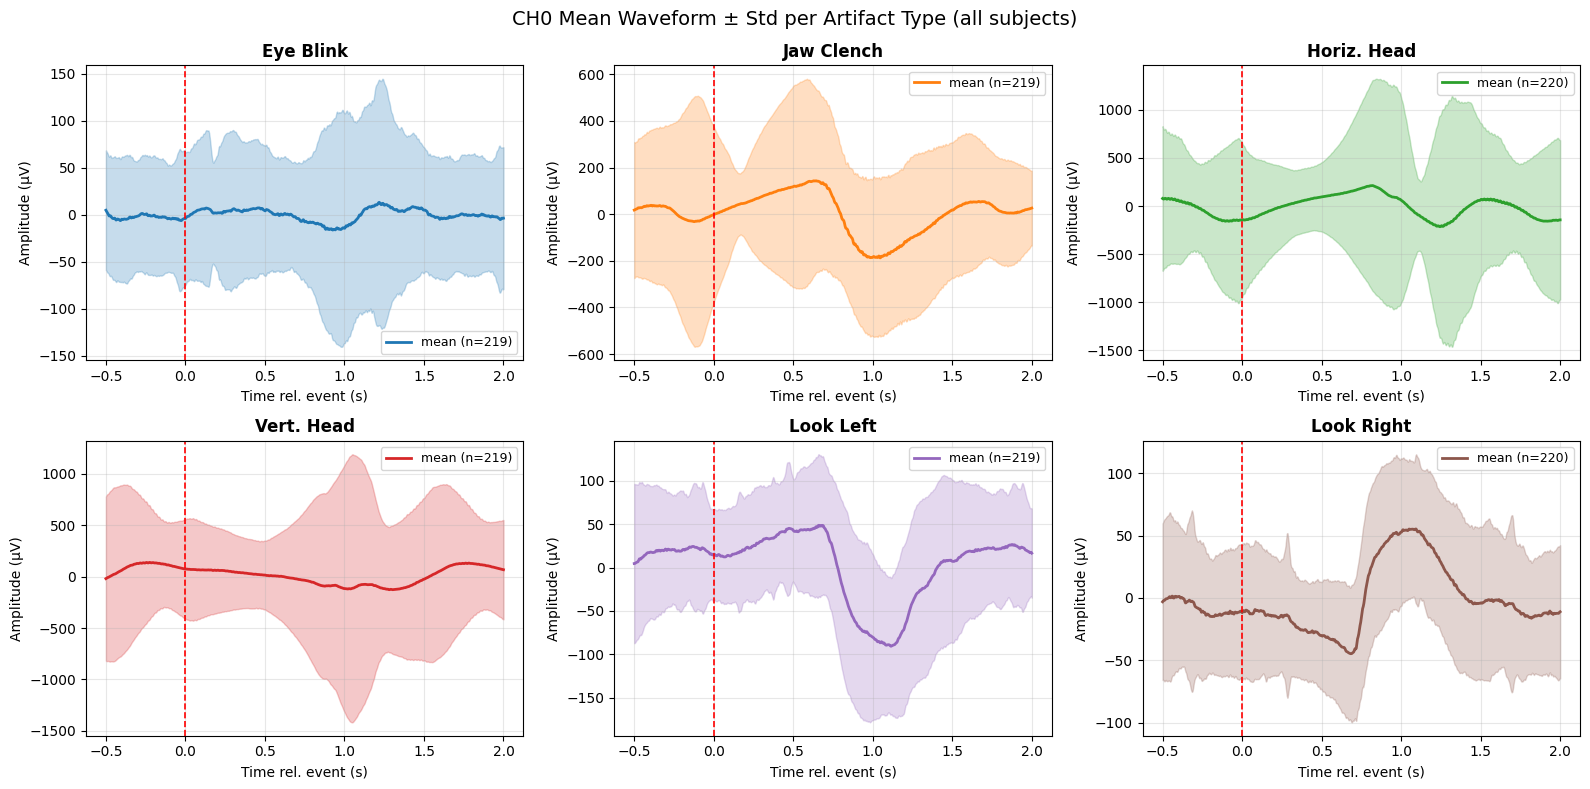

In [6]:
# Mean waveform ± std per artifact type — all subjects, CH0
T_BEFORE, T_AFTER = 0.5, 2.0
N_SAMP = int((T_BEFORE + T_AFTER) * FS)
t_axis = np.linspace(-T_BEFORE, T_AFTER, N_SAMP)

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=False)
axes = axes.flatten()

for idx, (ax, (event, label)) in enumerate(zip(axes, ART_LABELS.items())):
    waveforms = []
    for ep in all_epochs:
        if ep['artifact'].iloc[0] != event:
            continue
        x = ep['CH0'].values
        if len(x) >= N_SAMP:
            waveforms.append(x[:N_SAMP])

    if waveforms:
        W = np.array(waveforms)
        mean_w, std_w = W.mean(axis=0), W.std(axis=0)
        ax.plot(t_axis, mean_w, color=COLORS[idx], linewidth=2, label=f'mean (n={len(W)})')
        ax.fill_between(t_axis, mean_w - std_w, mean_w + std_w, alpha=0.25, color=COLORS[idx])

    ax.axvline(0, color='red', linestyle='--', linewidth=1.2)
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.set_xlabel('Time rel. event (s)')
    ax.set_ylabel('Amplitude (µV)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle('CH0 Mean Waveform ± Std per Artifact Type (all subjects)', fontsize=14)
plt.tight_layout()
plt.show()

## 1. Temporal Domain

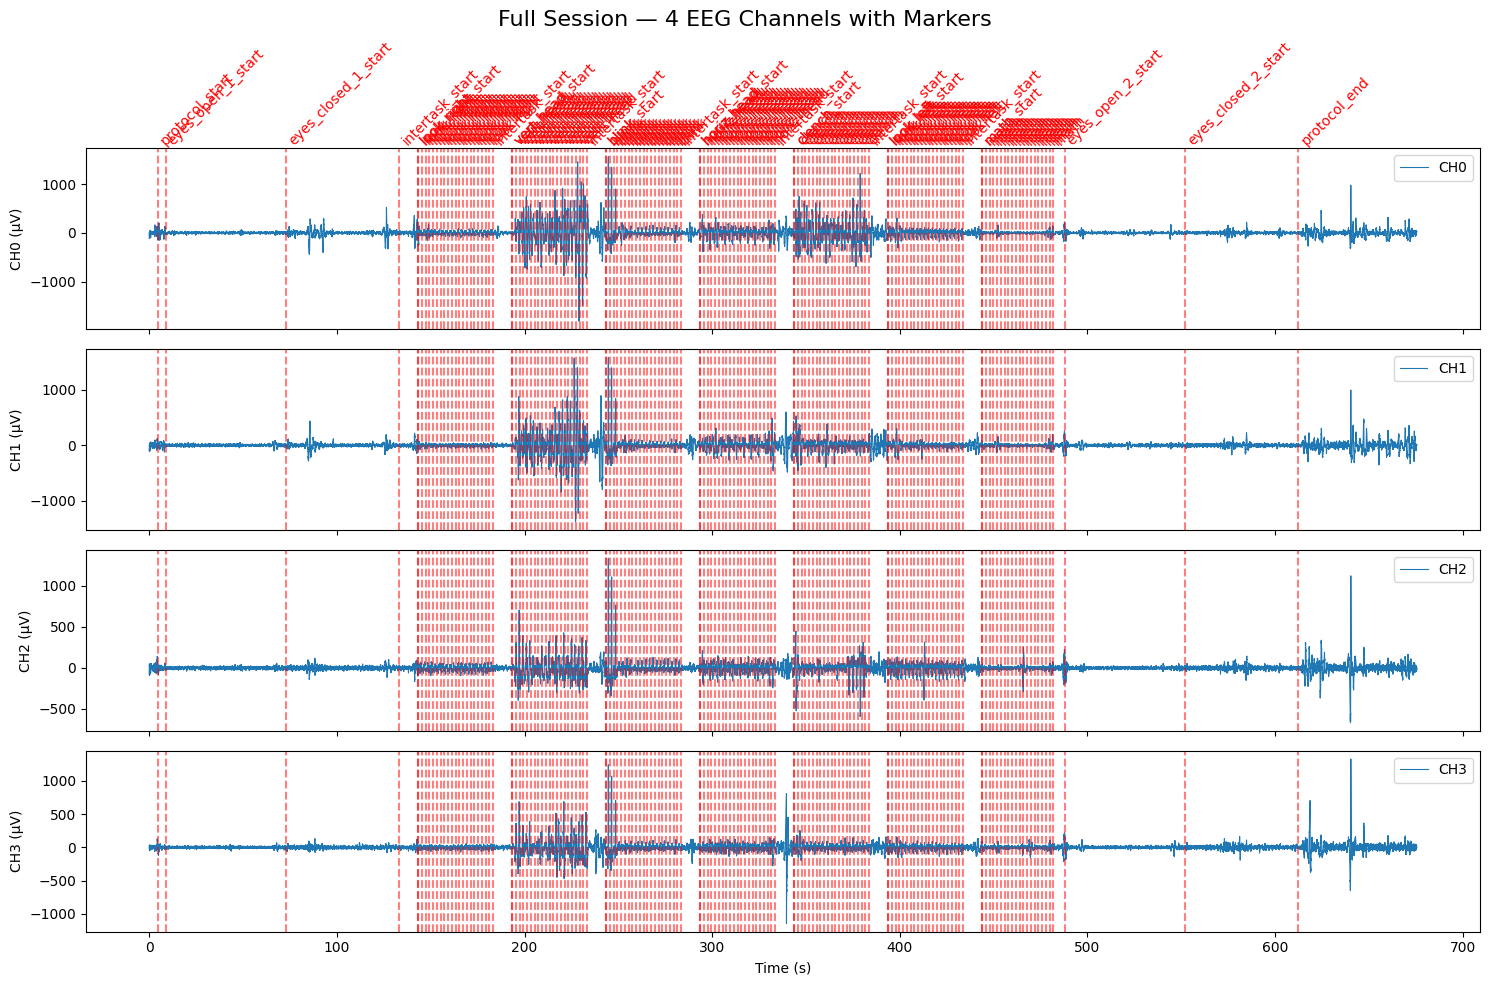

In [7]:
# Full session overview with markers
plot_4_channels_eeg(eeg0, mkr0, title='Full Session — 4 EEG Channels with Markers')

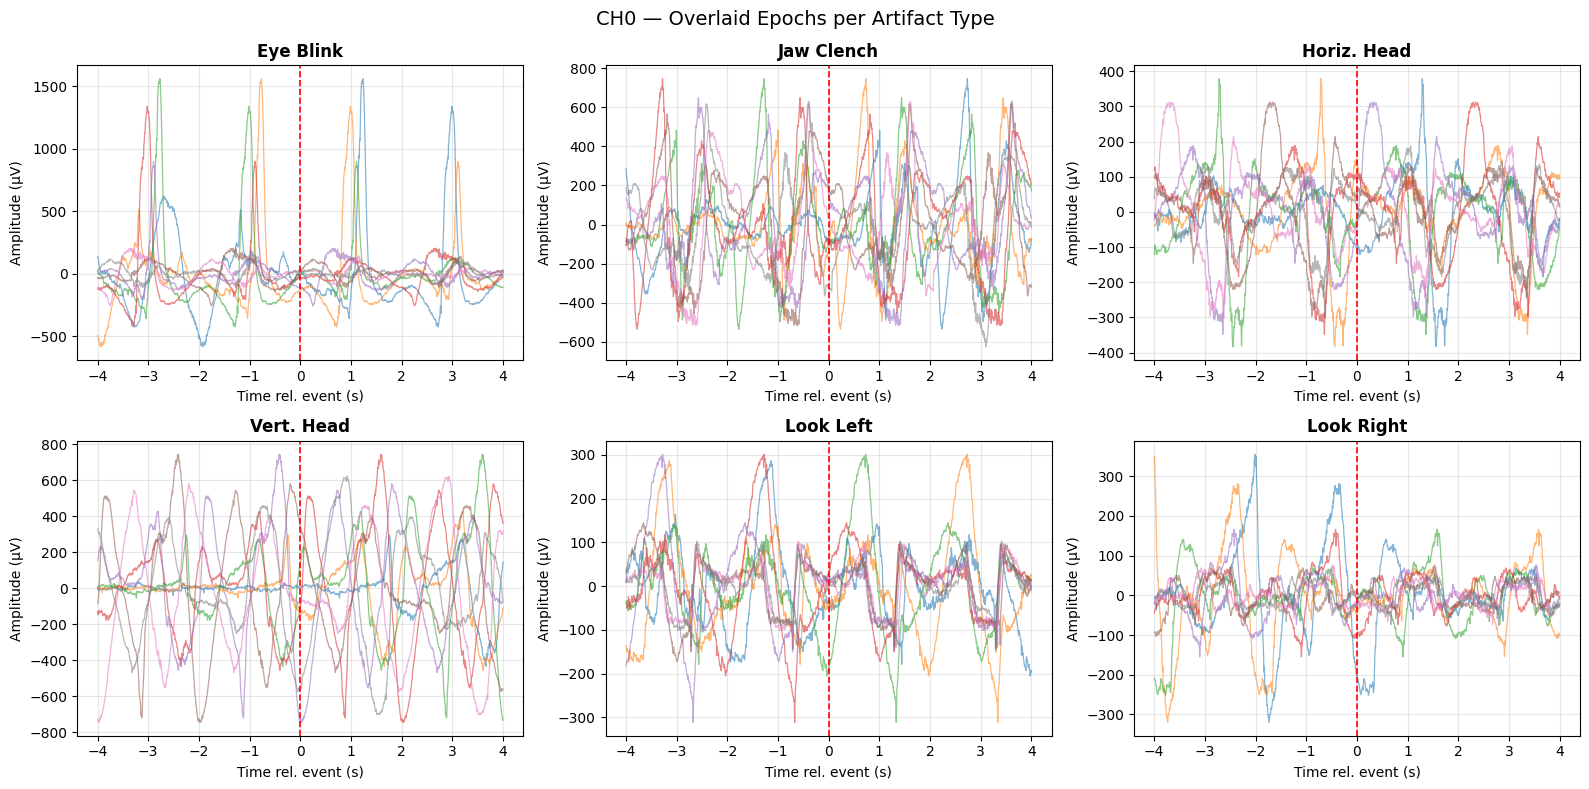

In [8]:
# Per-artifact-type overlaid epochs on CH0
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=False)
axes = axes.flatten()
t_before, t_after = 4.0, 4.0

for ax, (event, label) in zip(axes, ART_LABELS.items()):
    events_t = mkr0[mkr0['event'] == event]['time_rel'].values
    for i, t in enumerate(events_t[:8]):
        seg = eeg0[(eeg0['time_rel'] >= t - t_before) &
                   (eeg0['time_rel'] <= t + t_after)]
        t_axis = seg['time_rel'].values - t
        ax.plot(t_axis, seg['CH0'].values, alpha=0.55, linewidth=0.9, color=COLORS[i])
    ax.axvline(0, color='red', linestyle='--', linewidth=1.2, label='event')
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.set_xlabel('Time rel. event (s)')
    ax.set_ylabel('Amplitude (µV)')
    ax.grid(True, alpha=0.3)

fig.suptitle('CH0 — Overlaid Epochs per Artifact Type', fontsize=14)
plt.tight_layout()
plt.show()

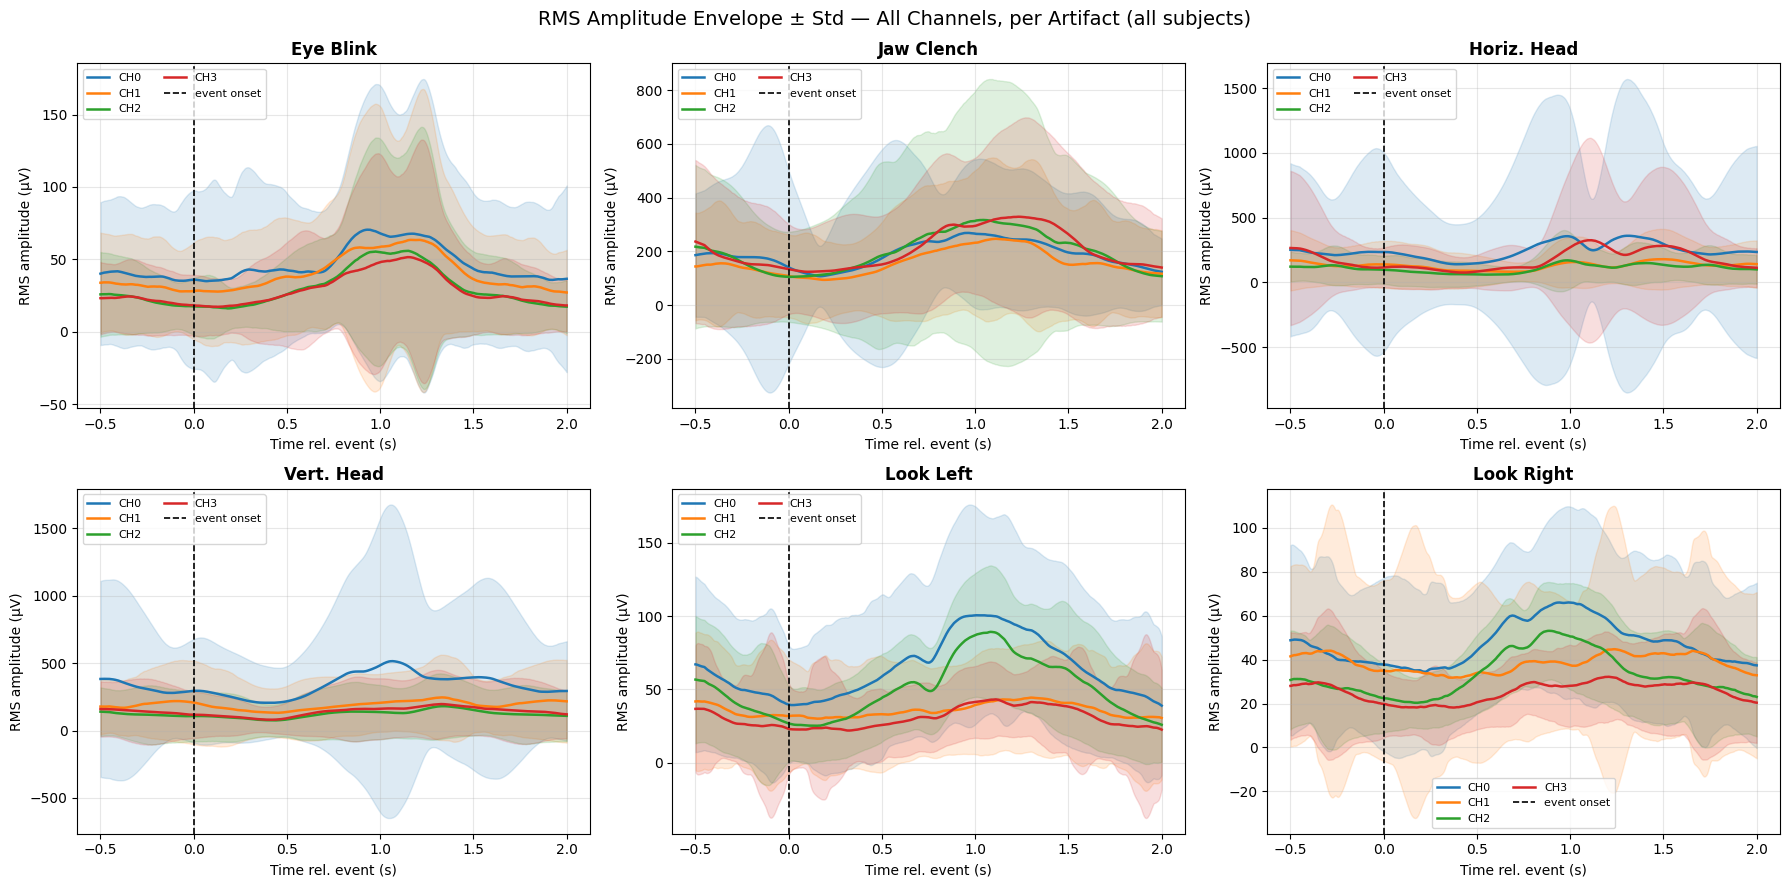

In [9]:
# RMS amplitude envelope — all 4 channels, per artifact type
WINDOW_ENV = int(FS * 0.1)
N_SAMP = int((T_BEFORE + T_AFTER) * FS)
t_axis_env = np.linspace(-T_BEFORE, T_AFTER, N_SAMP)
CH_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=False)
axes = axes.flatten()

for ax_idx, (ax, (event, label)) in enumerate(zip(axes, ART_LABELS.items())):
    for ci, ch in enumerate(CH):
        all_rms = []
        for ep in all_epochs:
            if ep['artifact'].iloc[0] != event:
                continue
            x = ep[ch].values.astype(float)
            if len(x) < N_SAMP:
                continue
            x = x[:N_SAMP]
            half = WINDOW_ENV // 2
            rms_env = np.array([
                np.sqrt(np.mean(x[max(0, j-half):j+half] ** 2))
                for j in range(N_SAMP)
            ])
            all_rms.append(rms_env)
        if all_rms:
            R = np.array(all_rms)
            m, s = R.mean(0), R.std(0)
            ax.plot(t_axis_env, m, color=CH_COLORS[ci], linewidth=1.8,
                    label=ch)
            ax.fill_between(t_axis_env, m - s, m + s, alpha=0.15,
                            color=CH_COLORS[ci])
    ax.axvline(0, color='black', linestyle='--', linewidth=1.2, label='event onset')
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.set_xlabel('Time rel. event (s)')
    ax.set_ylabel('RMS amplitude (µV)')
    ax.legend(fontsize=8, ncol=2)
    ax.grid(True, alpha=0.3)

fig.suptitle('RMS Amplitude Envelope ± Std — All Channels, per Artifact (all subjects)', fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
# Time-domain statistics — per artifact × channel
from scipy.stats import kurtosis as _kurt, skew as _skew

rows = []
for ep in all_epochs:
    event = ep['artifact'].iloc[0]
    label = ART_LABELS[event] if event in ART_LABELS else REST_LABEL
    for ch in CH:
        x = ep[ch].values.astype(float)
        rows.append({
            'artifact': label, 'channel': ch,
            'rms':      float(np.sqrt(np.mean(x**2))),
            'p2p':      float(x.max() - x.min()),
            'std':      float(x.std()),
            'kurtosis': float(_kurt(x, fisher=True)),
            'skewness': float(abs(_skew(x))),
            'var':      float(x.var()),
        })

feat_df = pd.DataFrame(rows)

# Mean per artifact × channel
pivot = feat_df.groupby(['artifact','channel'])[['rms','p2p','std','kurtosis','skewness']].mean().round(3)
print('Time-domain statistics (mean) — per artifact × channel:')
display(pivot)

Time-domain statistics (mean) — per artifact × channel:


rms       p2p      std  kurtosis  skewness
artifact    channel                                                
Eye Blink   CH0       61.675   307.537   61.370     1.167     0.832
            CH1       53.436   266.490   53.224     0.928     0.782
            CH2       43.240   233.812   43.073     1.676     0.943
            CH3       41.139   218.358   40.953     1.189     0.781
Horiz. Head CH0      279.723  1275.124  277.937     0.454     0.499
            CH1      147.719   711.170  146.887     0.537     0.448
            CH2      128.809   637.663  128.171     0.423     0.475
            CH3      202.225   959.426  200.729     0.491     0.484
Jaw Clench  CH0      273.341  1184.099  271.691     0.744     0.701
            CH1      181.350   842.276  179.908     0.855     0.828
            CH2      227.270   959.360  225.331     0.520     0.757
            CH3      261.466  1118.836  259.651     0.400     0.840
Look Left   CH0       93.528   434.691   92.806     0.065     0.683
            CH1       63.654   327.329   63.076     0.379     0.490
            CH2       78.122   378.399   77.461     0.161     0.721
            CH3       58.677   311.836   58.132     0.423     0.515
Look Right  CH0       52.582   238.061   52.362    -0.453     0.432
            CH1       43.222   217.605   43.040     0.179     0.474
            CH2       37.553   181.189   37.371    -0.291     0.498
            CH3       29.045   159.902   28.873     0.360     0.485
Rest        CH0      105.177   558.525  104.652     0.574     0.597
            CH1       56.117   285.320   55.733     0.083     0.393
            CH2       42.151   218.834   41.902     0.524     0.486
            CH3       59.475   310.597   59.095     0.520     0.495
Vert. Head  CH0      404.784  1670.360  401.034    -0.281     0.524
            CH1      227.391   998.979  225.229     0.560     0.603
            CH2      145.941   636.274  144.627     0.233     0.665
            CH3      169.151   752.514  167.637     0.366     0.653

## 2. Frequency Domain

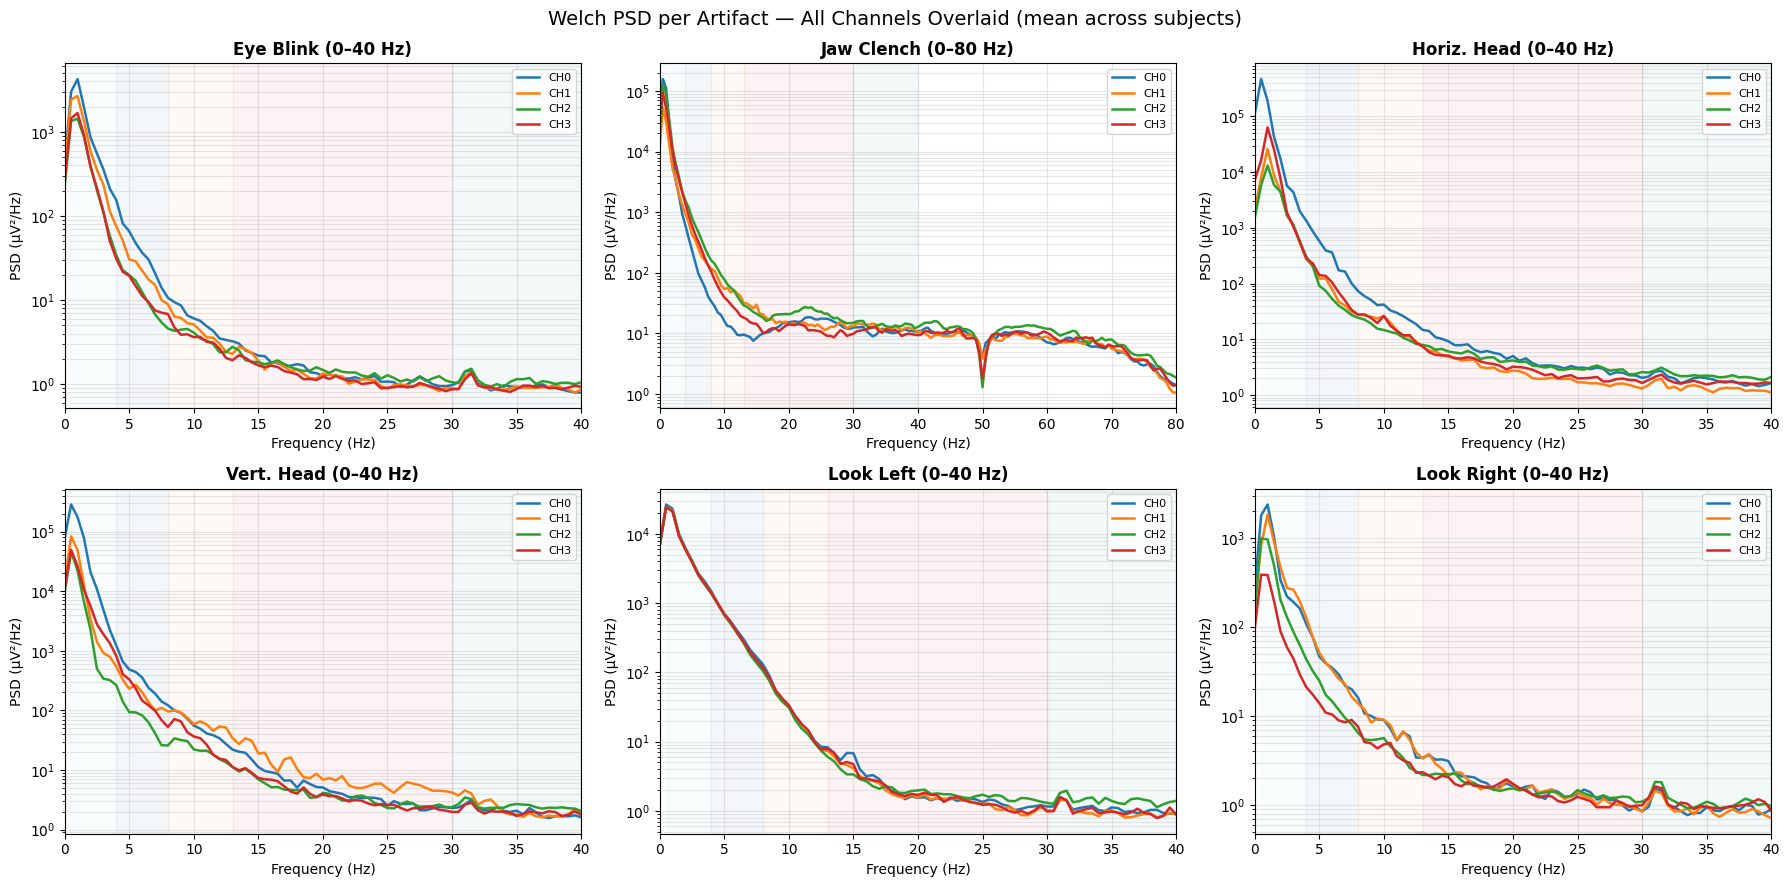

In [11]:
# Welch PSD per artifact — all 4 channels overlaid (mean across subjects)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()
BAND_COLORS = ['#a8dadc','#457b9d','#f4a261','#e63946','#2a9d8f']

for ax, (event, label) in zip(axes, ART_LABELS.items()):
    fmax = psd_freq_max(event)
    for ci, ch in enumerate(CH):
        psds = []
        freqs_ref = None
        for ep in all_epochs:
            if ep['artifact'].iloc[0] != event:
                continue
            x = ep[ch].values.astype(float)
            freqs, psd = signal.welch(x, fs=FS, nperseg=int(FS * 2))
            freqs_ref = freqs
            psds.append(psd)
        if psds and freqs_ref is not None:
            mean_psd = np.array(psds).mean(0)
            m = freqs_ref <= fmax
            ax.semilogy(freqs_ref[m], mean_psd[m], color=CH_COLORS[ci],
                        linewidth=1.8, label=ch)
    for bi, (bname, (lo, hi)) in enumerate(BANDS.items()):
        if hi <= fmax:
            ax.axvspan(lo, hi, alpha=0.06, color=BAND_COLORS[bi])
    ax.set_title(f"{label} (0–{int(fmax)} Hz)", fontsize=12, fontweight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('PSD (µV²/Hz)')
    ax.set_xlim(0, fmax)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which='both')

fig.suptitle('Welch PSD per Artifact — All Channels Overlaid (mean across subjects)', fontsize=14)
plt.tight_layout()
plt.show()


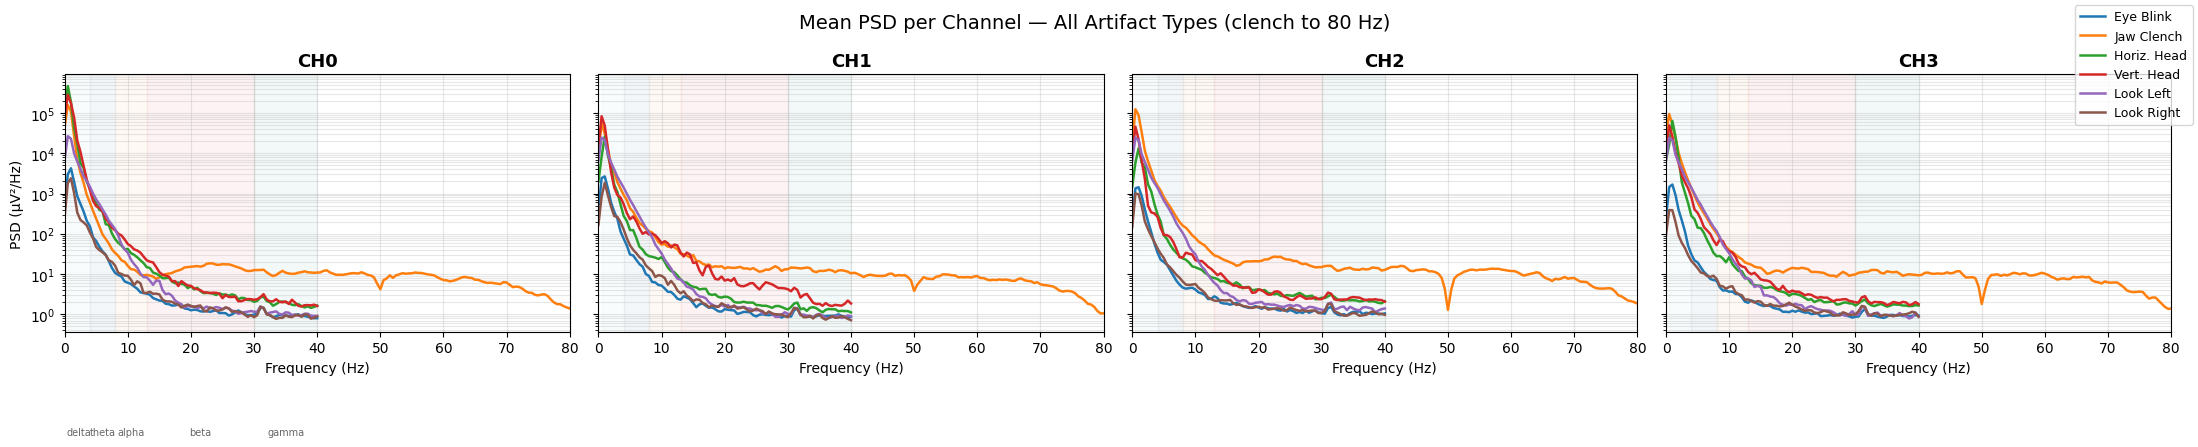

In [12]:
# PSD per channel — all artifact types overlaid (Jaw Clench to 80 Hz)
fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
BAND_COLORS = ['#a8dadc','#457b9d','#f4a261','#e63946','#2a9d8f']

for ci, (ax, ch) in enumerate(zip(axes, CH)):
    for ai, (event, label) in enumerate(ART_LABELS.items()):
        fmax = psd_freq_max(event)
        psds = []
        freqs_ref = None
        for ep in all_epochs:
            if ep['artifact'].iloc[0] != event:
                continue
            x = ep[ch].values.astype(float)
            freqs, psd = signal.welch(x, fs=FS, nperseg=int(FS * 2))
            freqs_ref = freqs
            psds.append(psd)
        if psds and freqs_ref is not None:
            mean_psd = np.array(psds).mean(0)
            m = freqs_ref <= fmax
            ax.semilogy(freqs_ref[m], mean_psd[m], color=COLORS[ai],
                        linewidth=1.8, label=label if ci == 0 else None)
    for bi, (bname, (lo, hi)) in enumerate(BANDS.items()):
        if hi <= PSD_MAX_HZ_CLENCH:
            ax.axvspan(lo, hi, alpha=0.06, color=BAND_COLORS[bi])
        if ci == 0:
            ax.text((lo+hi)/2, 1e-3, bname, ha='center', fontsize=7, alpha=0.6)
    ax.set_title(ch, fontsize=13, fontweight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_xlim(0, PSD_MAX_HZ_CLENCH)
    ax.grid(True, alpha=0.3, which='both')

axes[0].set_ylabel('PSD (µV²/Hz)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper right', fontsize=9)
fig.suptitle('Mean PSD per Channel — All Artifact Types (clench to 80 Hz)', fontsize=14)
plt.tight_layout()
plt.show()


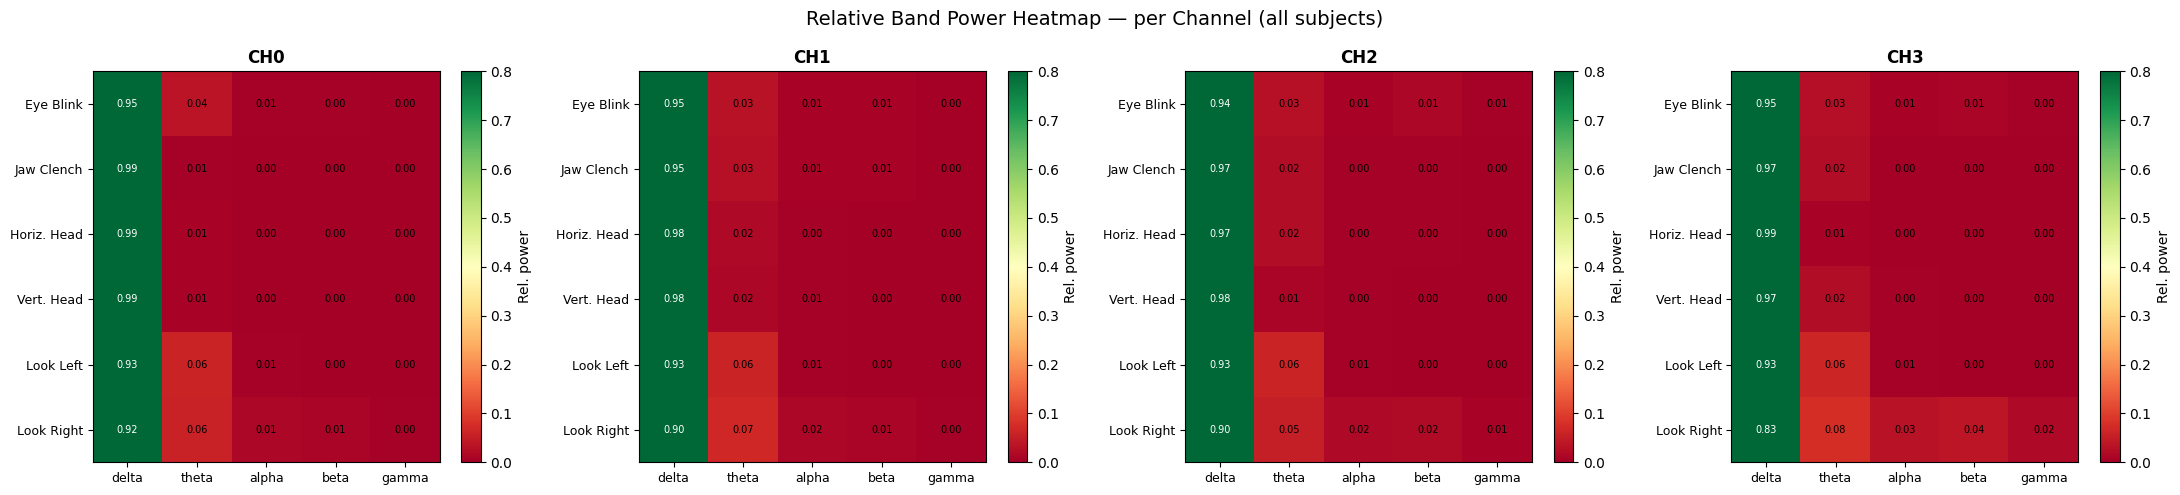

In [13]:
# Band power heatmap — absolute power, one subplot per channel
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, ch in zip(axes, CH):
    mat = {}
    for event, label in ART_LABELS.items():
        mat[label] = {}
        for bname, brange in BANDS.items():
            vals = [band_power(ep[ch].values.astype(float), FS, brange)
                    for ep in all_epochs if ep['artifact'].iloc[0] == event]
            mat[label][bname] = float(np.mean(vals)) if vals else 0.0
    df_mat = pd.DataFrame(mat).T
    df_norm = df_mat.div(df_mat.sum(axis=1), axis=0)

    im = ax.imshow(df_norm.values, aspect='auto', cmap='RdYlGn', vmin=0, vmax=0.8)
    ax.set_xticks(range(len(BANDS)))
    ax.set_xticklabels(list(BANDS.keys()), fontsize=9)
    ax.set_yticks(range(len(df_norm)))
    ax.set_yticklabels(df_norm.index, fontsize=9)
    ax.set_title(ch, fontsize=12, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Rel. power')
    for i in range(len(df_norm)):
        for j in range(df_norm.shape[1]):
            ax.text(j, i, f'{df_norm.iloc[i,j]:.2f}',
                    ha='center', va='center', fontsize=7,
                    color='black' if df_norm.iloc[i,j] < 0.5 else 'white')

fig.suptitle('Relative Band Power Heatmap — per Channel (all subjects)', fontsize=14)
plt.tight_layout()
plt.show()

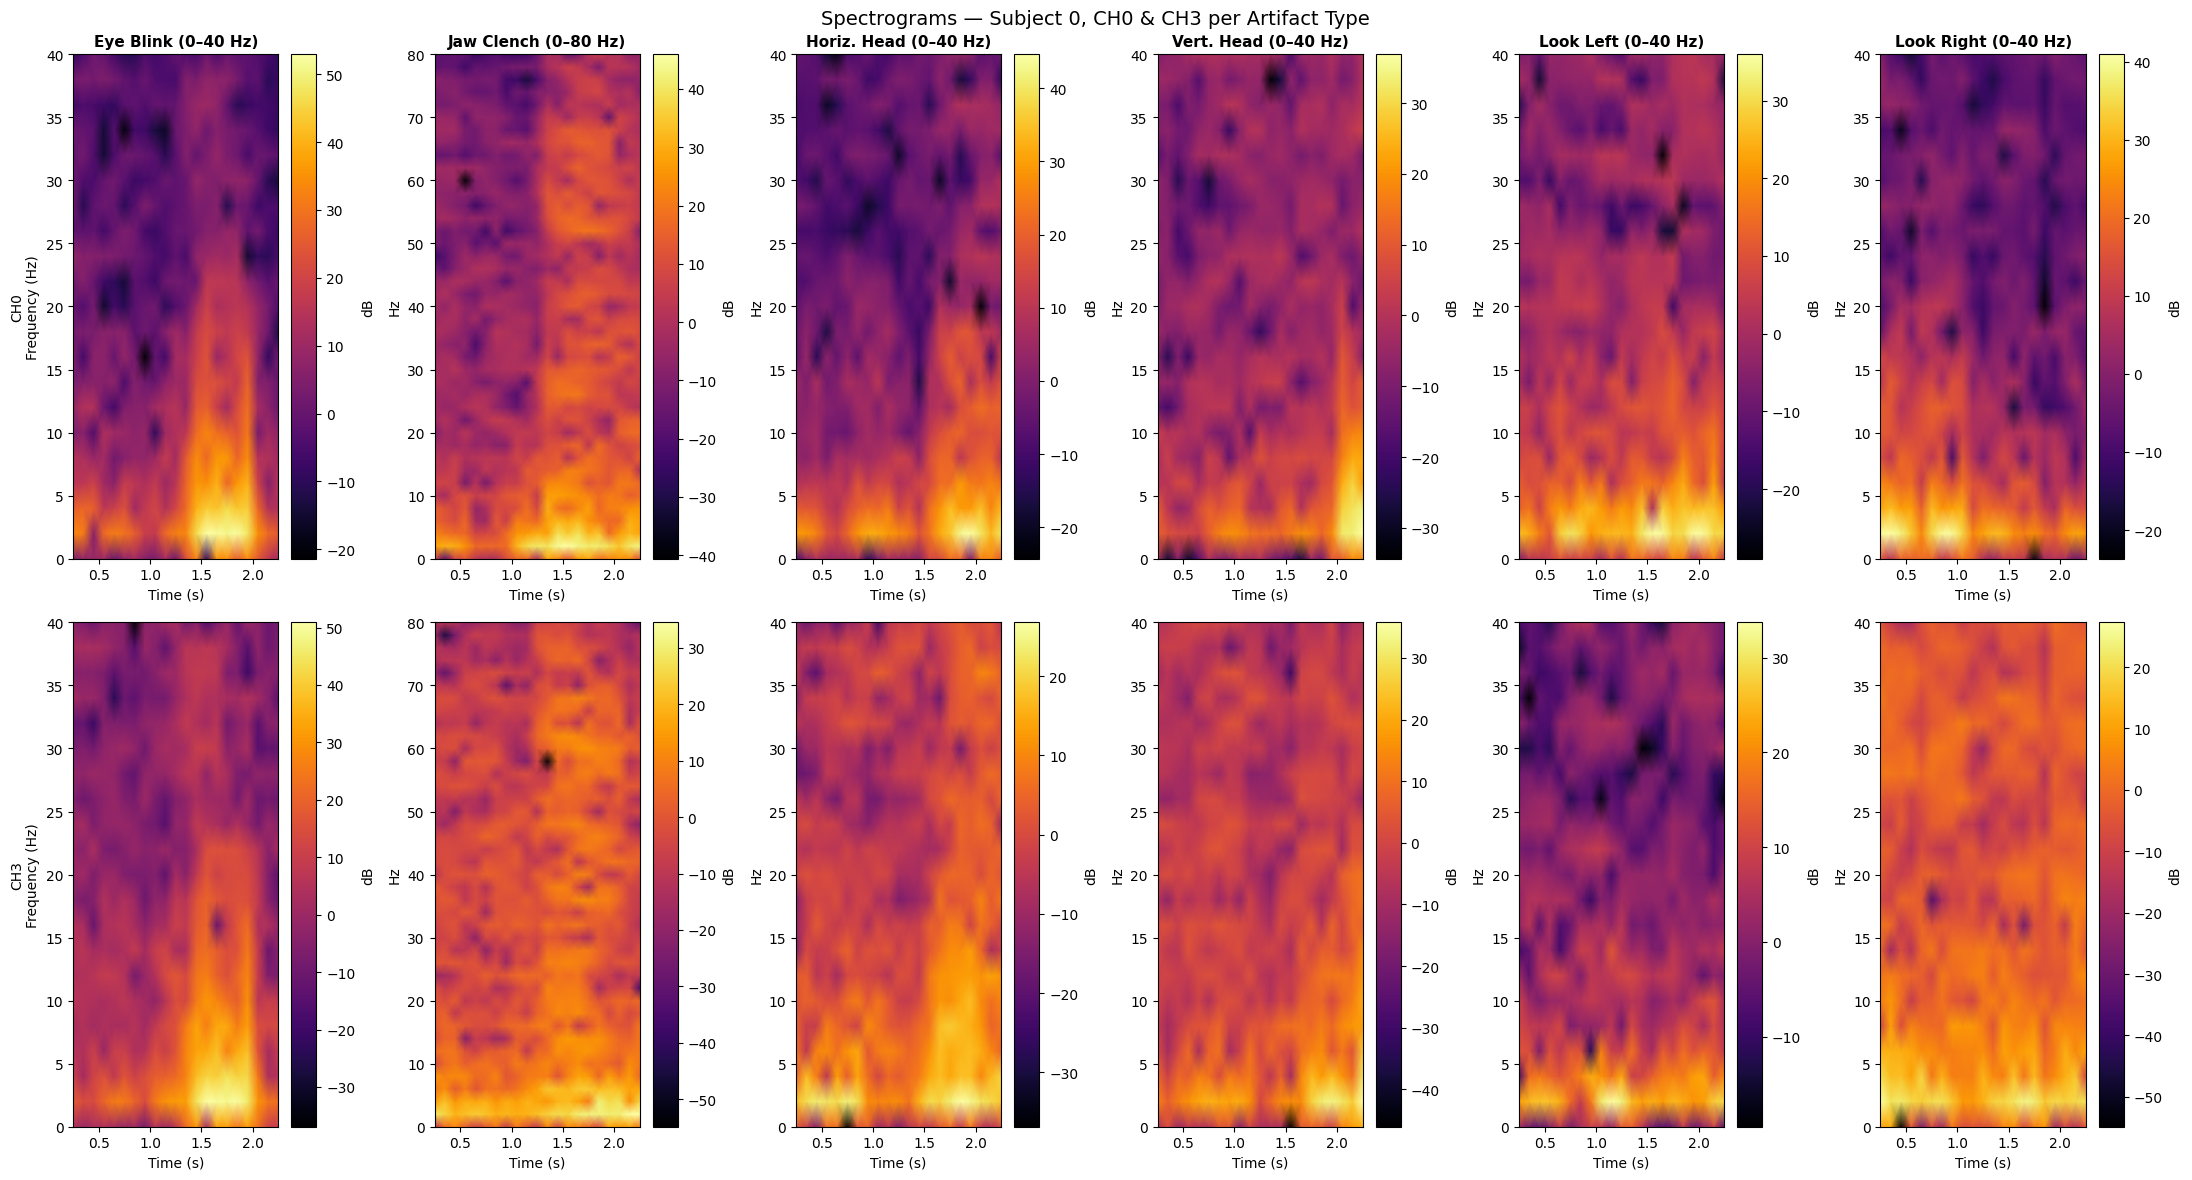

In [14]:
# Spectrograms — Subject 0, CH0 and CH3, per artifact
subj0_id = eeg0['subject'].iloc[0]
SHOW_CH = ['CH0', 'CH3']

fig, axes = plt.subplots(len(SHOW_CH), len(ART_LABELS),
                          figsize=(22, 6 * len(SHOW_CH)))

for ri, ch in enumerate(SHOW_CH):
    for ci, (event, label) in enumerate(ART_LABELS.items()):
        ax = axes[ri, ci]
        fmax = psd_freq_max(event)
        cands = [ep for ep in all_epochs
                 if ep['artifact'].iloc[0] == event
                 and ep['subject'].iloc[0] == subj0_id]
        if not cands:
            ax.set_visible(False)
            continue
        x = cands[0][ch].values.astype(float)
        f_sg, t_sg, Sxx = signal.spectrogram(
            x, fs=FS, nperseg=int(FS*0.5), noverlap=int(FS*0.4))
        mask = f_sg <= fmax
        im = ax.pcolormesh(t_sg, f_sg[mask],
                            10*np.log10(Sxx[mask]+1e-12),
                            shading='gouraud', cmap='inferno')
        plt.colorbar(im, ax=ax, label='dB')
        ax.set_ylim(0, fmax)
        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Hz')
        if ri == 0:
            ax.set_title(f"{label} (0–{int(fmax)} Hz)", fontsize=11, fontweight='bold')
        if ci == 0:
            ax.set_ylabel(f'{ch}\nFrequency (Hz)', fontsize=10)

fig.suptitle('Spectrograms — Subject 0, CH0 & CH3 per Artifact Type', fontsize=14)
plt.tight_layout()
plt.show()


## 3. Statistical Distributions

In [15]:
# Feature extraction — all epochs, all channels
feat_rows2 = []
for ep in all_epochs:
    event = ep['artifact'].iloc[0]
    label = ART_LABELS[event] if event in ART_LABELS else REST_LABEL
    subj  = ep['subject'].iloc[0]
    for ch in CH:
        f = epoch_features(ep, ch=ch)
        f['artifact'] = label
        f['channel']  = ch
        f['subject']  = subj
        feat_rows2.append(f)

feat_full = pd.DataFrame(feat_rows2)
TIME_FEATS = ['rms', 'p2p', 'kurtosis', 'skewness', 'var']
BAND_FEATS = [f'bp_{b}' for b in BANDS]
ALL_FEATS  = TIME_FEATS + BAND_FEATS

print(f'Feature matrix: {feat_full.shape}')
display(
    feat_full.groupby(['artifact','channel'])[TIME_FEATS].mean().round(3)
)


Feature matrix: (5952, 13)


rms       p2p  kurtosis  skewness         var
artifact    channel                                                   
Eye Blink   CH0       61.675   307.537     1.167     0.832    7262.941
            CH1       53.436   266.490     0.928     0.782    5379.071
            CH2       43.240   233.812     1.676     0.943    3769.081
            CH3       41.139   218.358     1.189     0.781    3659.997
Horiz. Head CH0      279.723  1275.124     0.454     0.499  522979.433
            CH1      147.719   711.170     0.537     0.448   42892.894
            CH2      128.809   637.663     0.423     0.475   28746.359
            CH3      202.225   959.426     0.491     0.484  162449.197
Jaw Clench  CH0      273.341  1184.099     0.744     0.701  157441.781
            CH1      181.350   842.276     0.855     0.828   66201.756
            CH2      227.270   959.360     0.520     0.757  141079.090
            CH3      261.466  1118.836     0.400     0.840  124833.380
Look Left   CH0       93.528   434.691     0.065     0.683   45127.073
            CH1       63.654   327.329     0.379     0.490   42670.834
            CH2       78.122   378.399     0.161     0.721   42665.729
            CH3       58.677   311.836     0.423     0.515   42185.865
Look Right  CH0       52.582   238.061    -0.453     0.432    3458.292
            CH1       43.222   217.605     0.179     0.474    3167.014
            CH2       37.553   181.189    -0.291     0.498    1561.885
            CH3       29.045   159.902     0.360     0.485    1031.498
Rest        CH0      105.177   558.525     0.574     0.597  130838.688
            CH1       56.117   285.320     0.083     0.393    7711.316
            CH2       42.151   218.834     0.524     0.486    6169.410
            CH3       59.475   310.597     0.520     0.495   12860.359
Vert. Head  CH0      404.784  1670.360    -0.281     0.524  441636.468
            CH1      227.391   998.979     0.560     0.603   93236.428
            CH2      145.941   636.274     0.233     0.665   49465.386
            CH3      169.151   752.514     0.366     0.653   61802.697

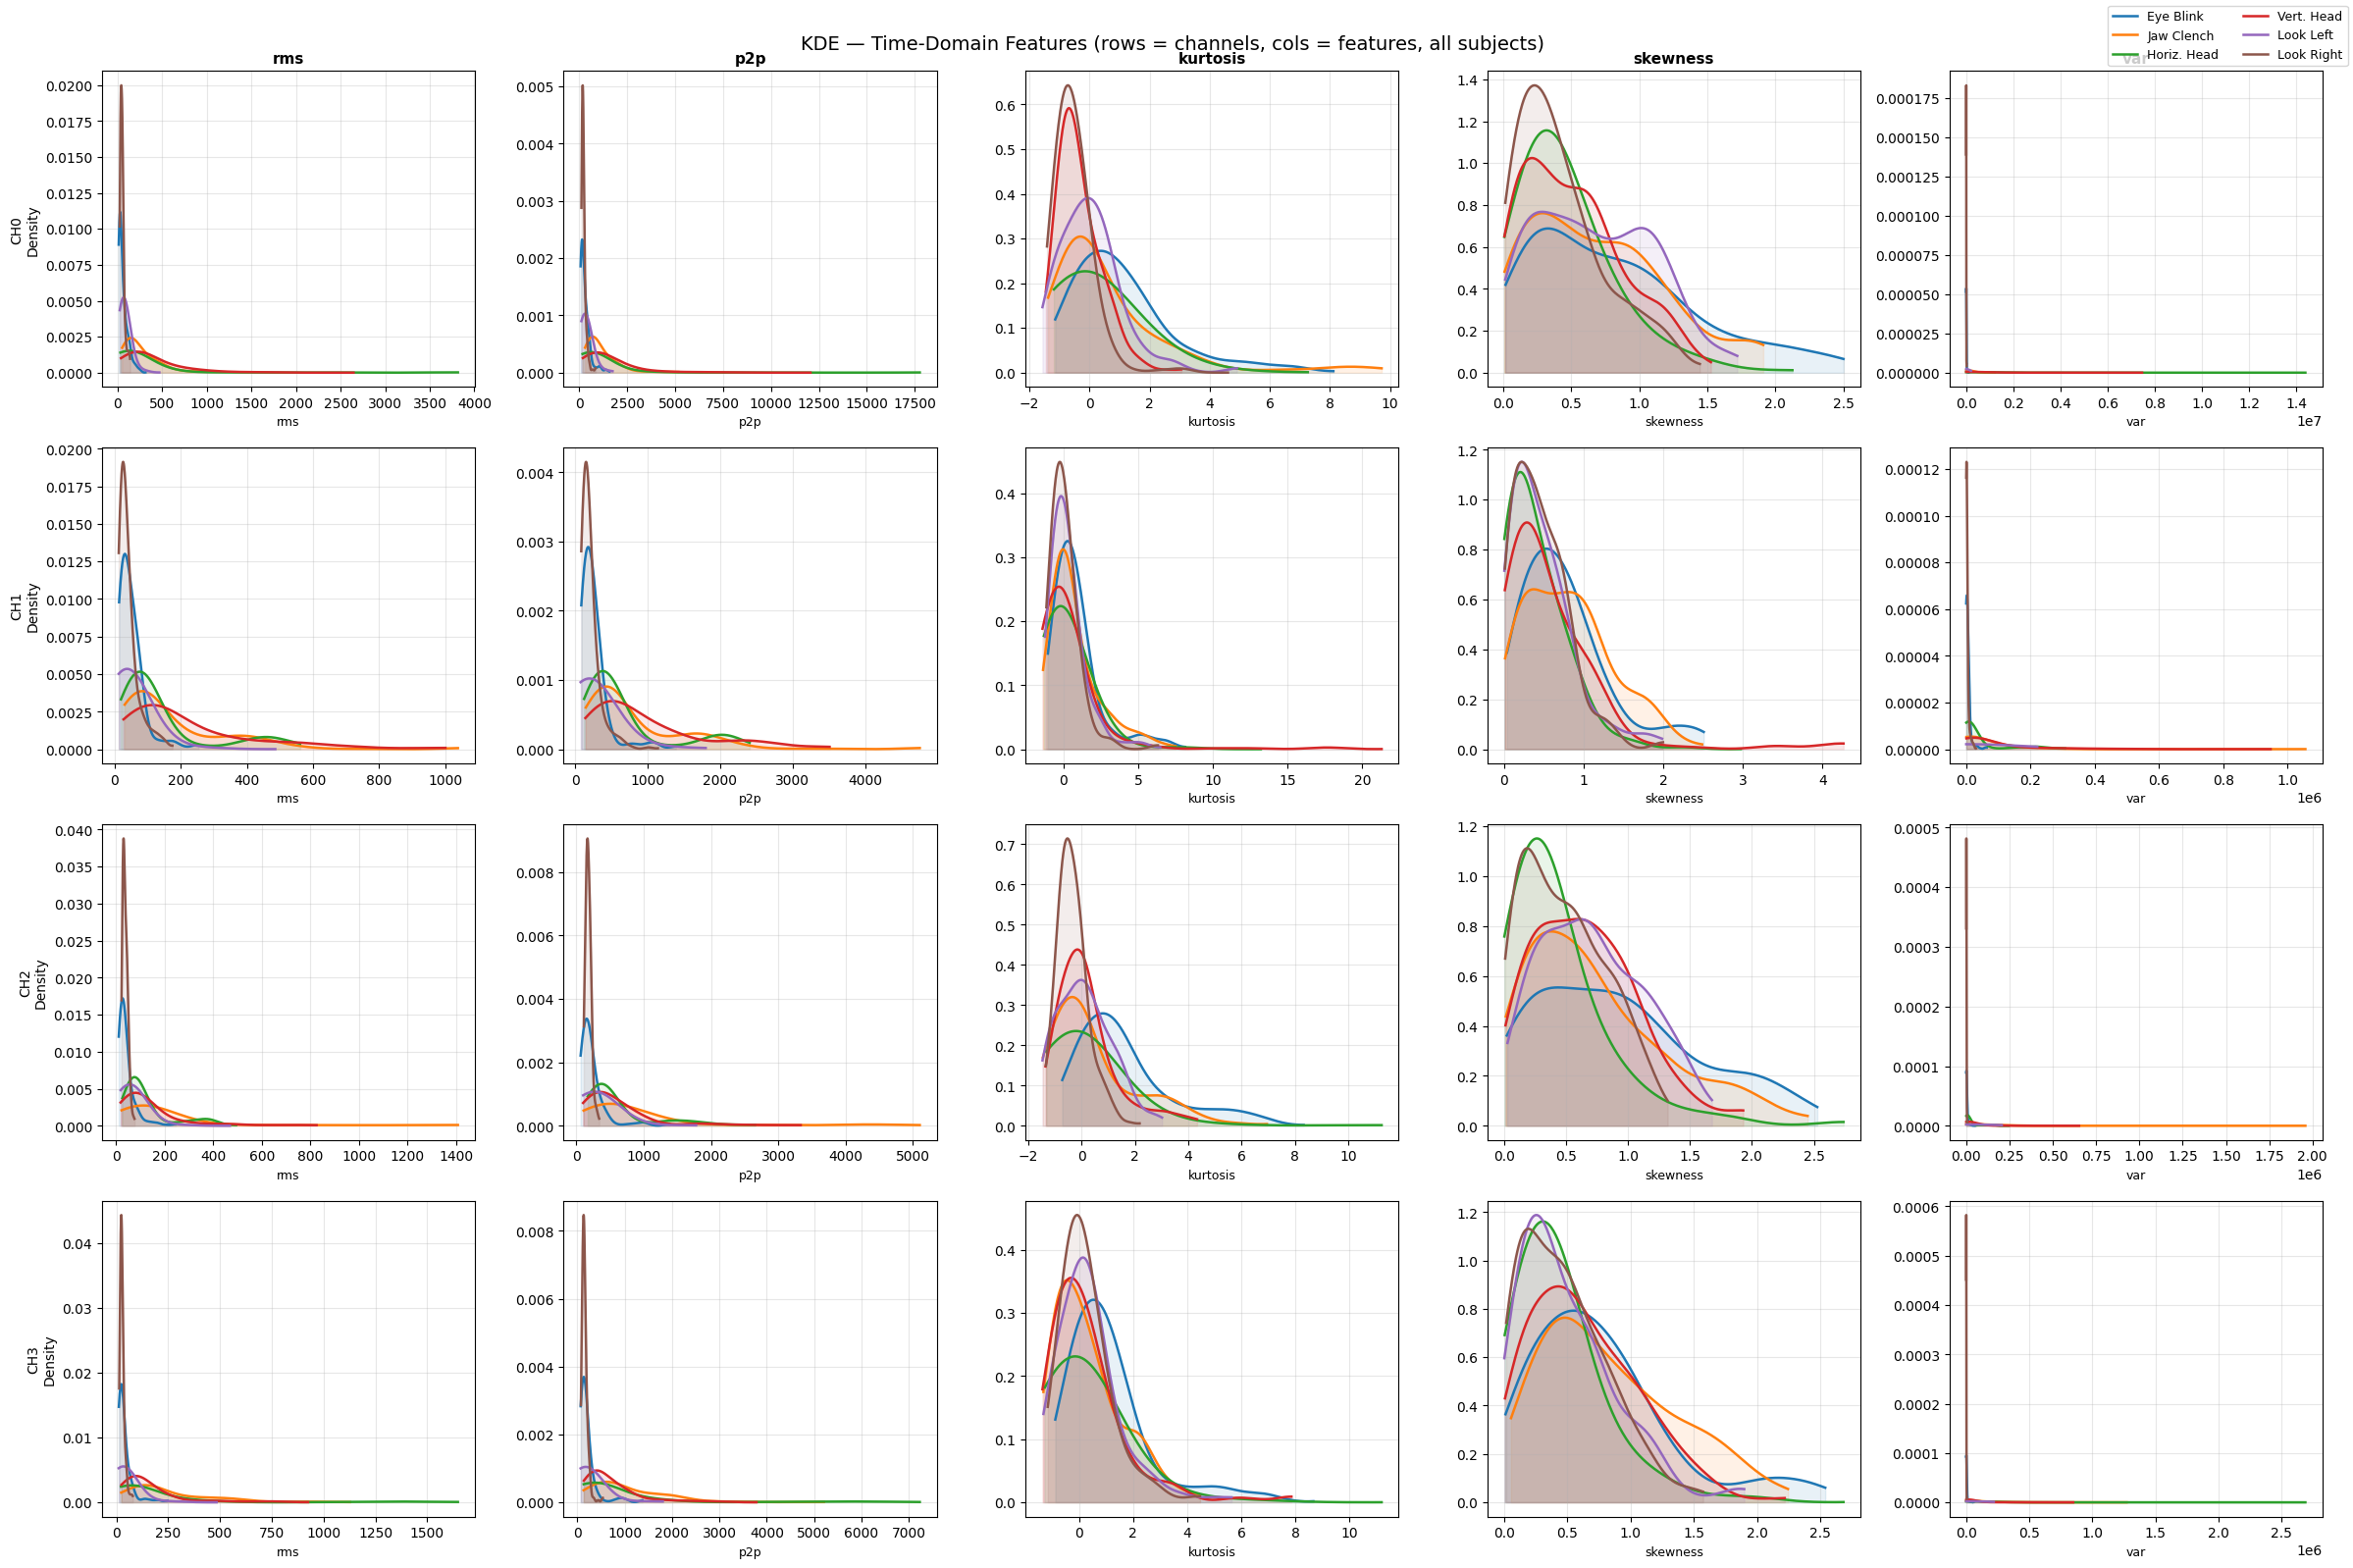

In [16]:
# KDE — time-domain features, rows = channels, cols = features
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(len(CH), len(TIME_FEATS),
                          figsize=(24, 4 * len(CH)), sharey=False)

for ri, ch in enumerate(CH):
    df_ch = feat_full[feat_full['channel'] == ch]
    for ci, feat in enumerate(TIME_FEATS):
        ax = axes[ri, ci]
        for ai, (event, label) in enumerate(ART_LABELS.items()):
            vals = df_ch.loc[df_ch['artifact'] == label, feat].dropna().values
            if len(vals) < 5:
                continue
            lo, hi = np.percentile(vals, 1), np.percentile(vals, 99)
            x_r = np.linspace(lo, hi, 300)
            try:
                kde = gaussian_kde(vals, bw_method='scott')
                ax.plot(x_r, kde(x_r), color=COLORS[ai], linewidth=1.8,
                        label=label if (ri == 0 and ci == 0) else None)
                ax.fill_between(x_r, kde(x_r), alpha=0.10, color=COLORS[ai])
            except Exception:
                pass
        ax.set_xlabel(feat, fontsize=9)
        ax.grid(True, alpha=0.3)
        if ci == 0:
            ax.set_ylabel(f'{ch}\nDensity', fontsize=10)
        if ri == 0:
            ax.set_title(feat, fontsize=11, fontweight='bold')

handles, lbl = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, lbl, loc='upper right', fontsize=9, ncol=2)
fig.suptitle('KDE — Time-Domain Features (rows = channels, cols = features, all subjects)',
             fontsize=14)
plt.tight_layout()
plt.show()

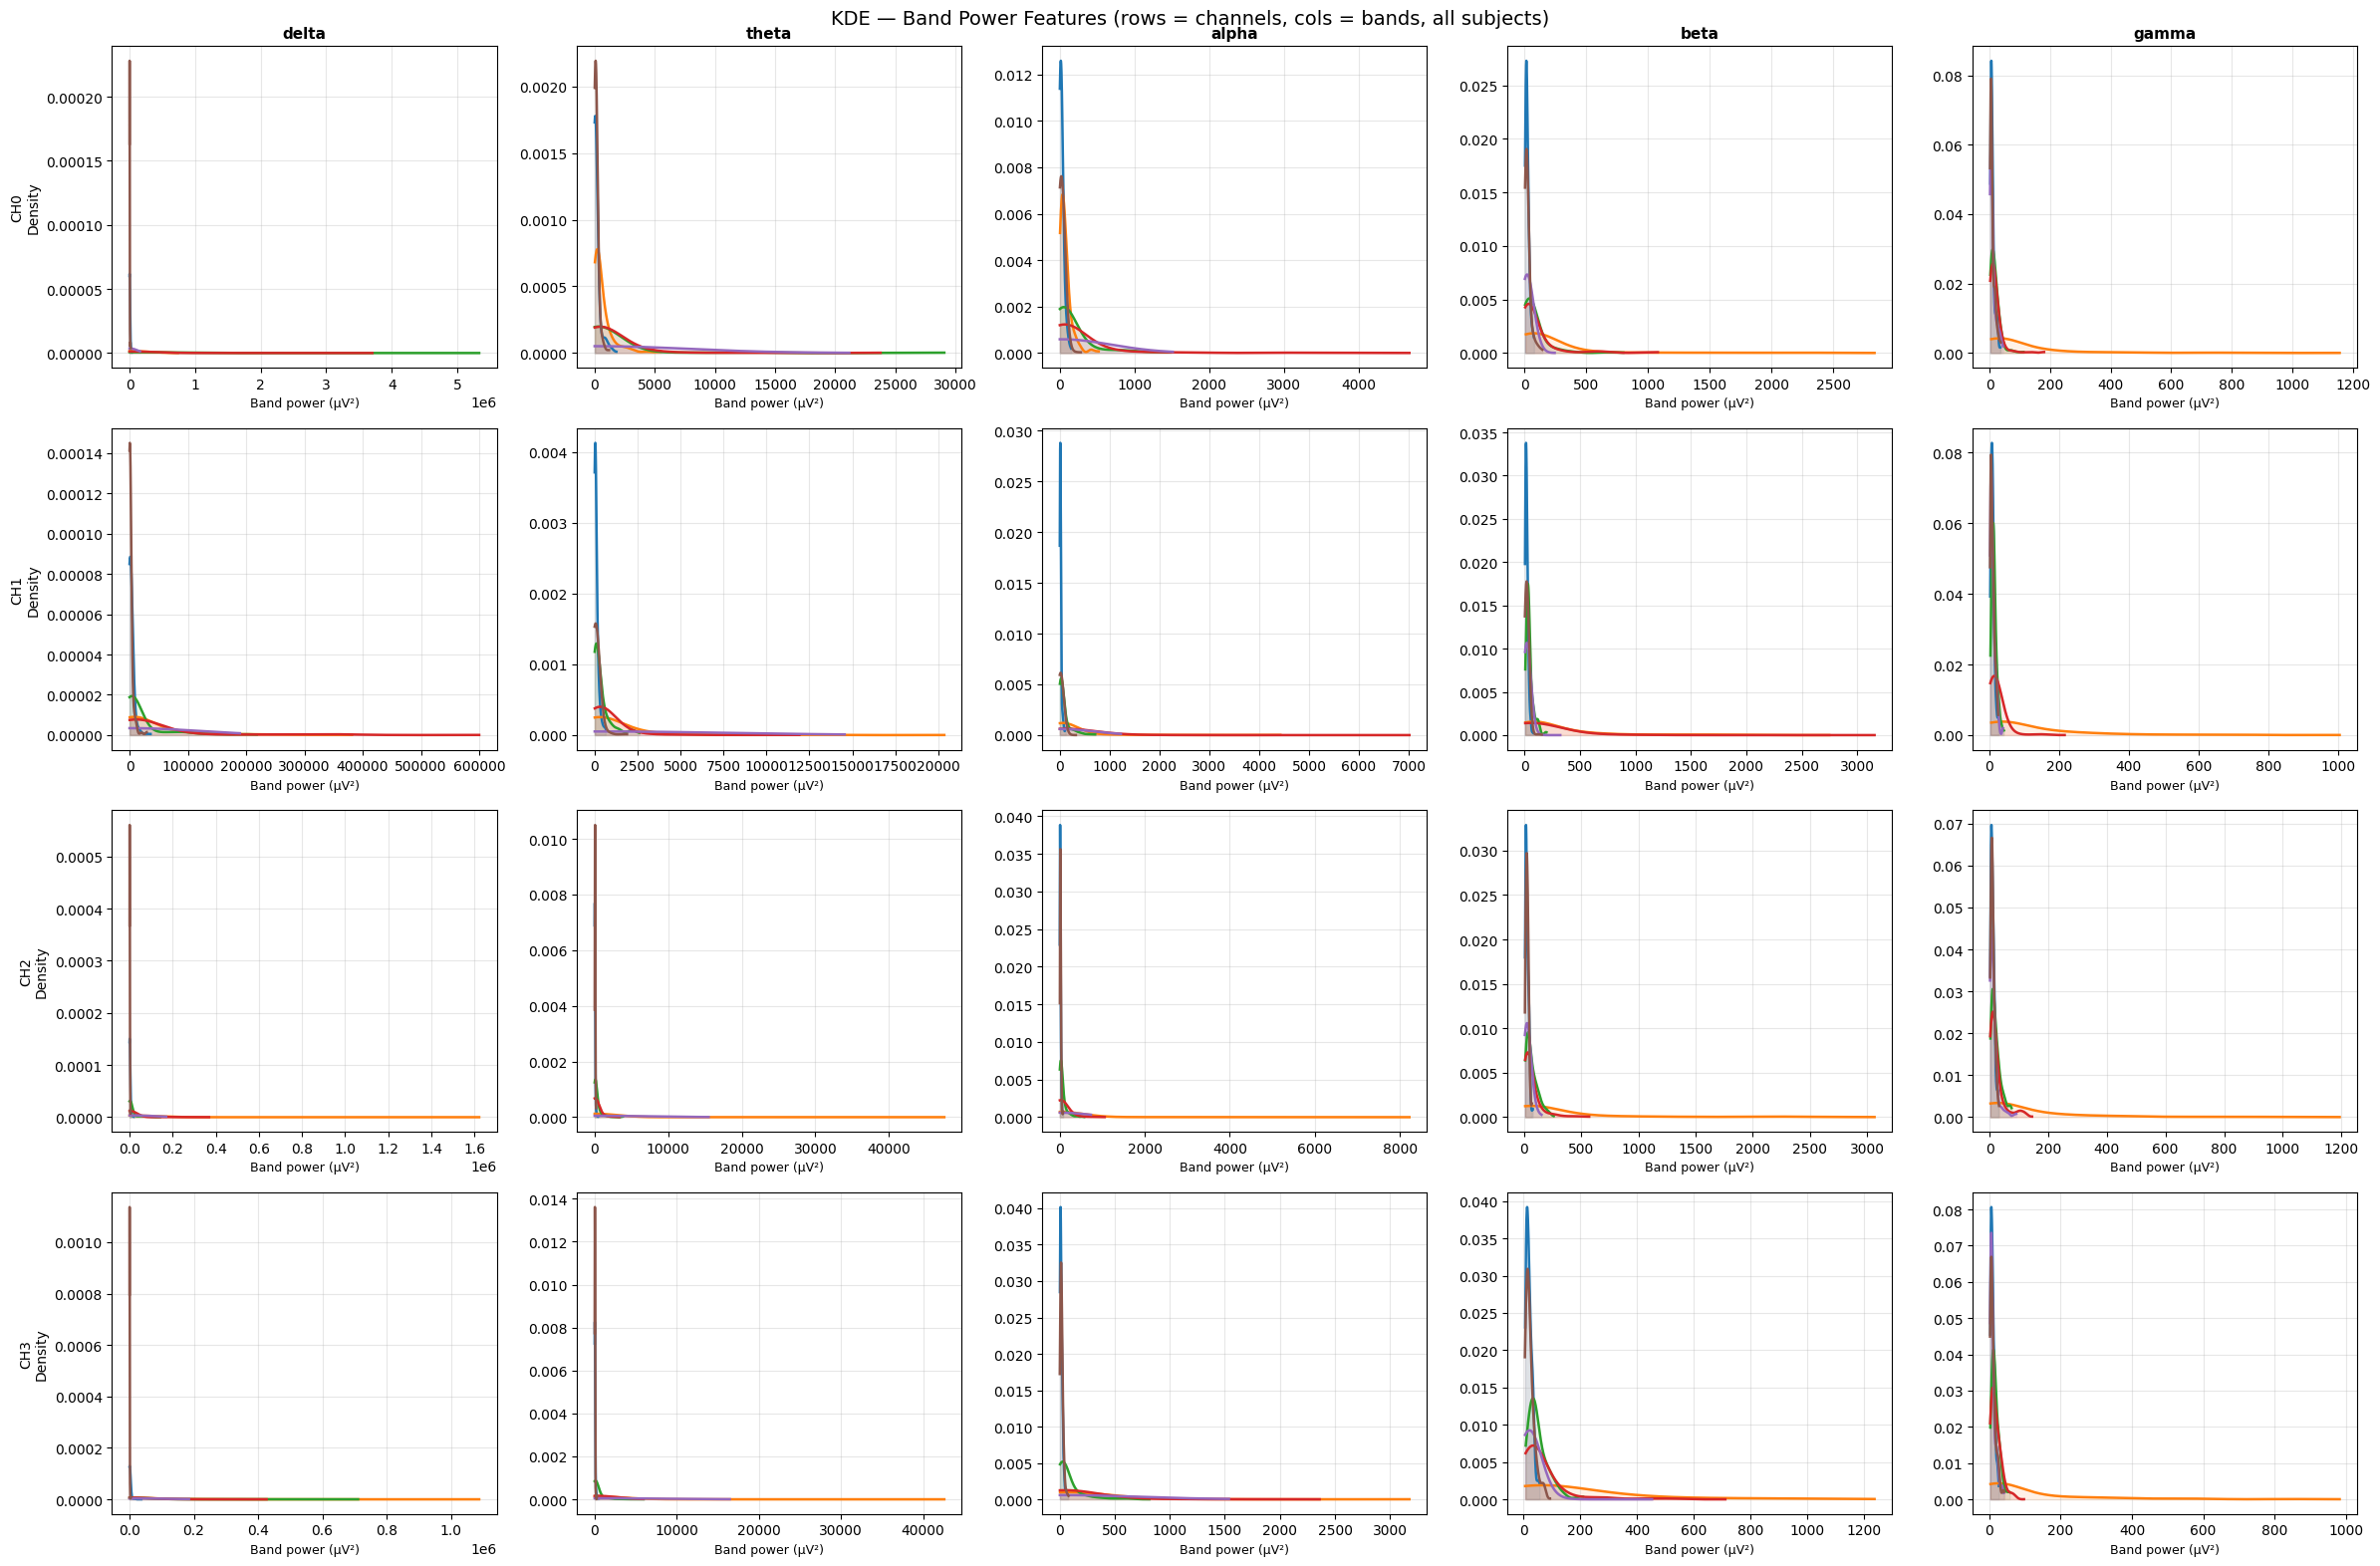

In [17]:
# KDE — band power features, rows = channels, cols = bands
fig, axes = plt.subplots(len(CH), len(BAND_FEATS),
                          figsize=(24, 4 * len(CH)), sharey=False)

for ri, ch in enumerate(CH):
    df_ch = feat_full[feat_full['channel'] == ch]
    for ci, feat in enumerate(BAND_FEATS):
        ax = axes[ri, ci]
        bname = feat.replace('bp_', '')
        for ai, (event, label) in enumerate(ART_LABELS.items()):
            vals = df_ch.loc[df_ch['artifact'] == label, feat].dropna().values
            if len(vals) < 5:
                continue
            lo, hi = max(0, np.percentile(vals, 1)), np.percentile(vals, 99)
            x_r = np.linspace(lo, hi, 300)
            try:
                kde = gaussian_kde(vals, bw_method='scott')
                ax.plot(x_r, kde(x_r), color=COLORS[ai], linewidth=1.8)
                ax.fill_between(x_r, kde(x_r), alpha=0.10, color=COLORS[ai])
            except Exception:
                pass
        ax.set_xlabel('Band power (µV²)', fontsize=9)
        ax.grid(True, alpha=0.3)
        if ci == 0:
            ax.set_ylabel(f'{ch}\nDensity', fontsize=10)
        if ri == 0:
            ax.set_title(bname, fontsize=11, fontweight='bold')

fig.suptitle('KDE — Band Power Features (rows = channels, cols = bands, all subjects)',
             fontsize=14)
plt.tight_layout()
plt.show()

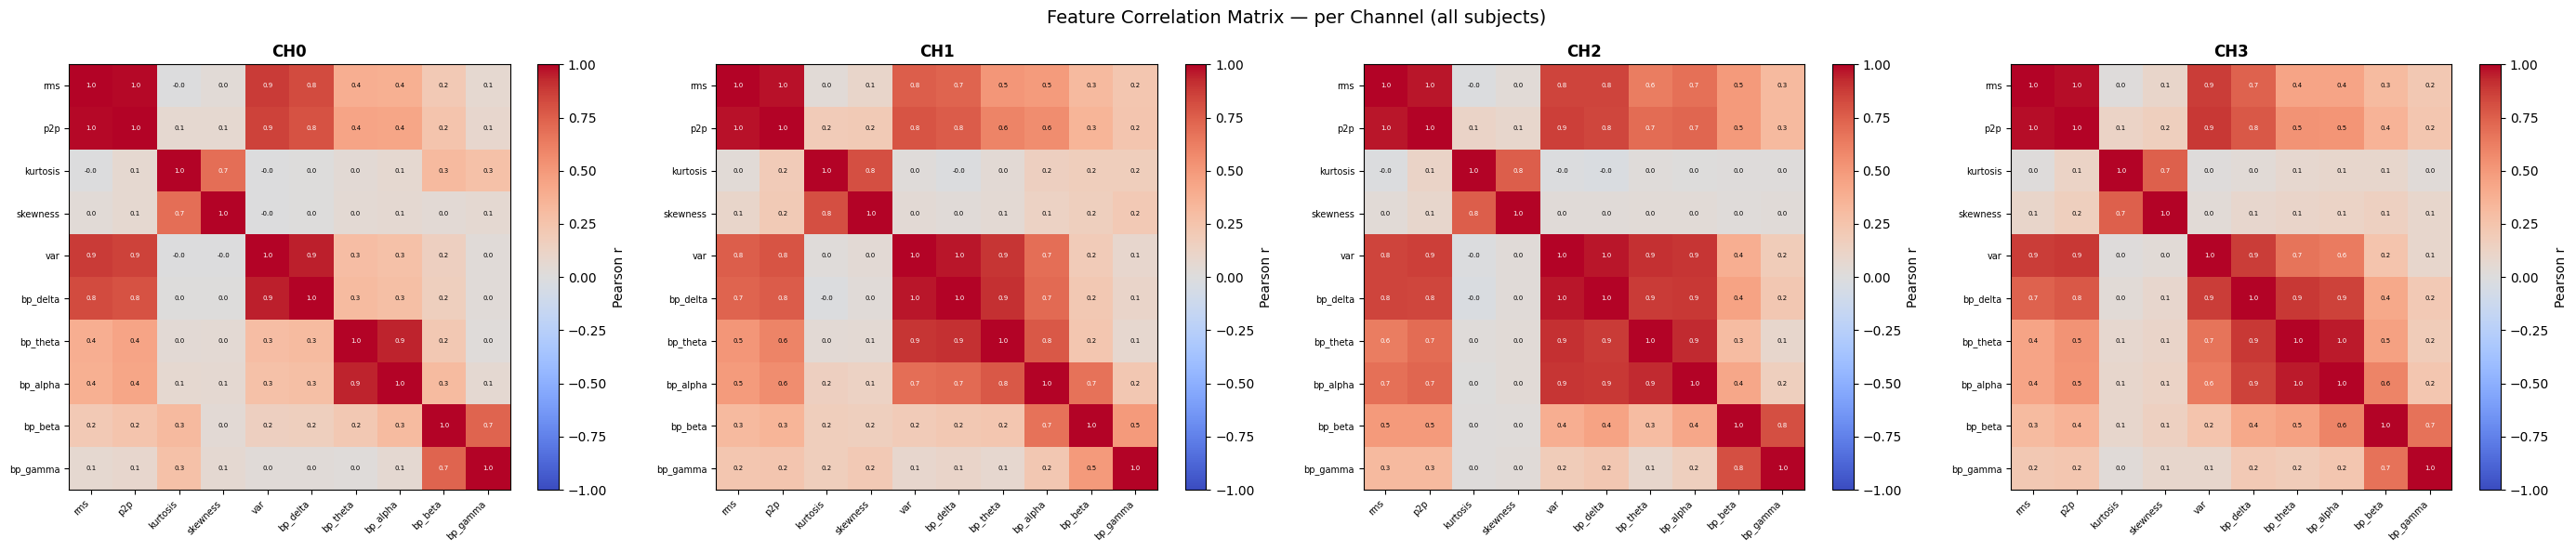

In [18]:
# Feature correlation matrix — one subplot per channel
fig, axes = plt.subplots(1, 4, figsize=(28, 6))

for ax, ch in zip(axes, CH):
    df_ch = feat_full[feat_full['channel'] == ch][ALL_FEATS]
    corr = df_ch.corr()
    im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
    ax.set_xticks(range(len(ALL_FEATS)))
    ax.set_xticklabels(ALL_FEATS, rotation=45, ha='right', fontsize=7)
    ax.set_yticks(range(len(ALL_FEATS)))
    ax.set_yticklabels(ALL_FEATS, fontsize=7)
    ax.set_title(ch, fontsize=12, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Pearson r')
    for i in range(len(ALL_FEATS)):
        for j in range(len(ALL_FEATS)):
            ax.text(j, i, f'{corr.iloc[i,j]:.1f}', ha='center', va='center',
                    fontsize=5, color='black' if abs(corr.iloc[i,j]) < 0.6 else 'white')

fig.suptitle('Feature Correlation Matrix — per Channel (all subjects)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Boxplots

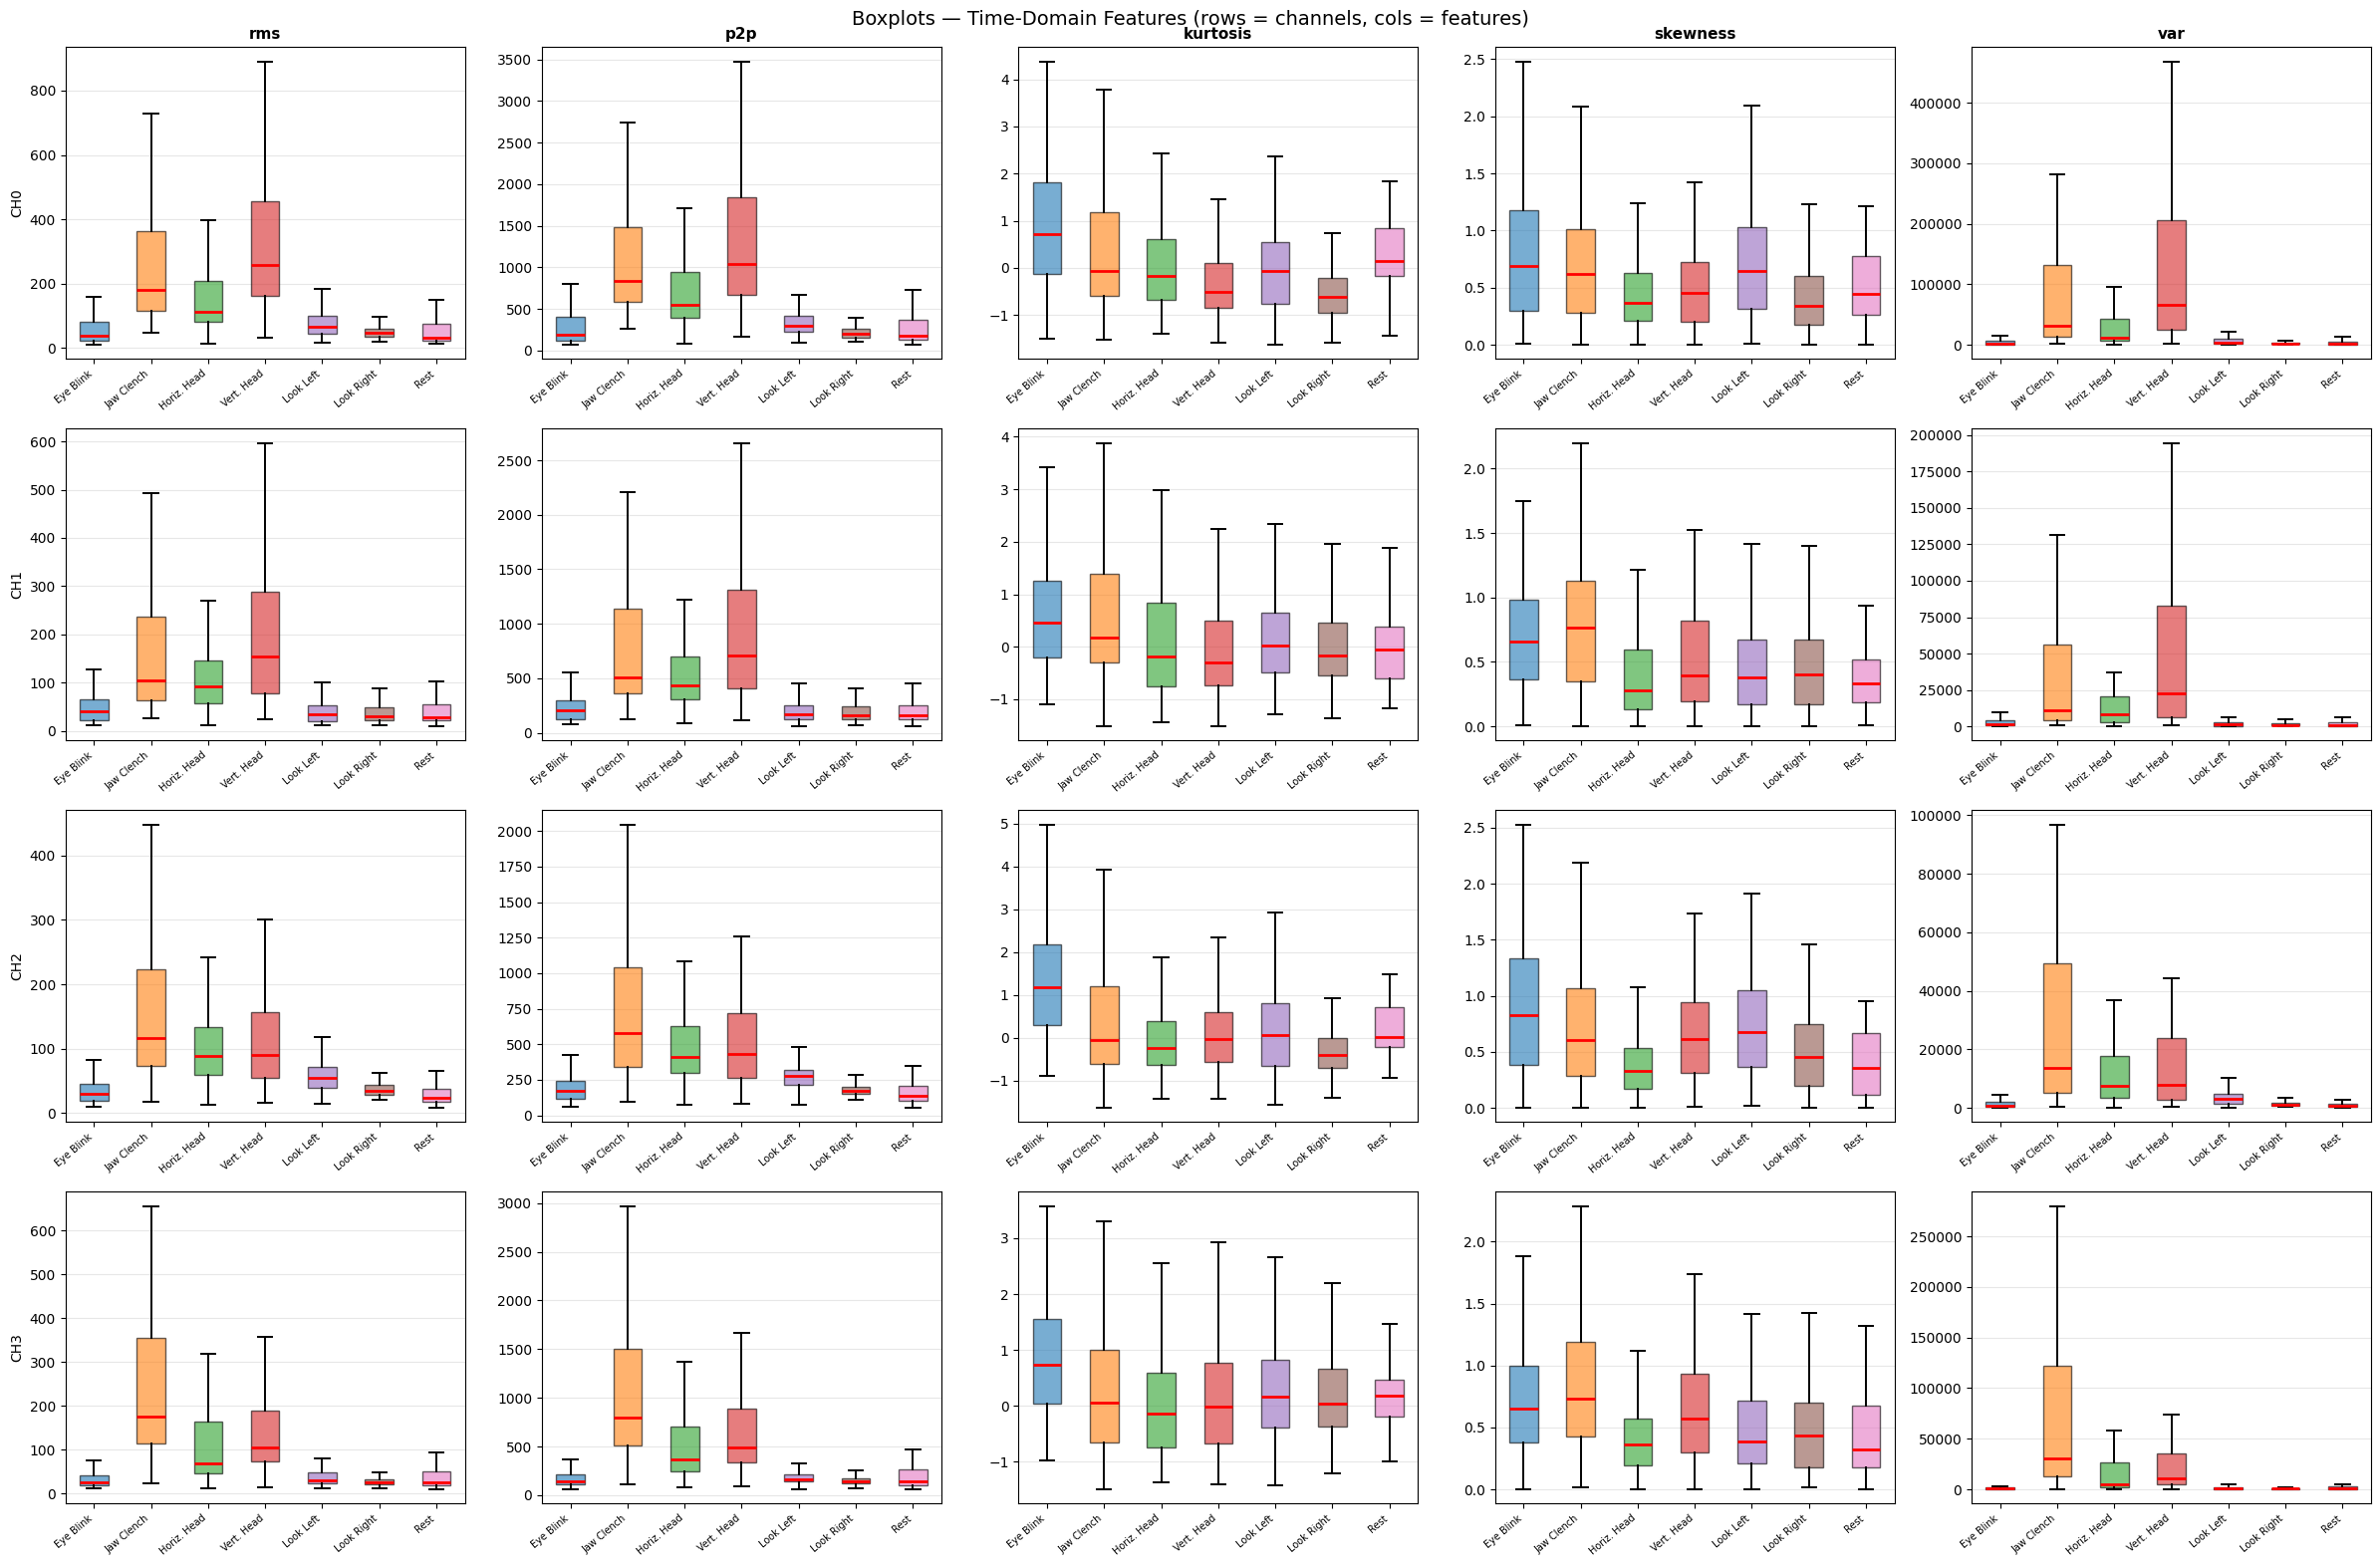

In [19]:
# Boxplots — time-domain features, rows = channels, cols = features
art_labels_list = list(ART_LABELS.values()) + [REST_LABEL]

fig, axes = plt.subplots(len(CH), len(TIME_FEATS),
                          figsize=(24, 4 * len(CH)), sharey=False)

for ri, ch in enumerate(CH):
    df_ch = feat_full[feat_full['channel'] == ch]
    for ci, feat in enumerate(TIME_FEATS):
        ax = axes[ri, ci]
        data = [df_ch.loc[df_ch['artifact'] == lbl, feat].dropna().values
                for lbl in art_labels_list]
        bp = ax.boxplot(data, labels=art_labels_list,
                        patch_artist=True, showfliers=False,
                        medianprops=dict(color='red', linewidth=2),
                        whiskerprops=dict(linewidth=1.4),
                        capprops=dict(linewidth=1.4))
        for patch, col in zip(bp['boxes'], COLORS[:len(art_labels_list)]):
            patch.set_facecolor(col)
            patch.set_alpha(0.6)
        ax.set_xticklabels(art_labels_list, rotation=40, ha='right', fontsize=7)
        ax.grid(True, alpha=0.3, axis='y')
        if ri == 0:
            ax.set_title(feat, fontsize=11, fontweight='bold')
        if ci == 0:
            ax.set_ylabel(f'{ch}', fontsize=10)

fig.suptitle('Boxplots — Time-Domain Features (rows = channels, cols = features)', fontsize=14)
plt.tight_layout()
plt.show()


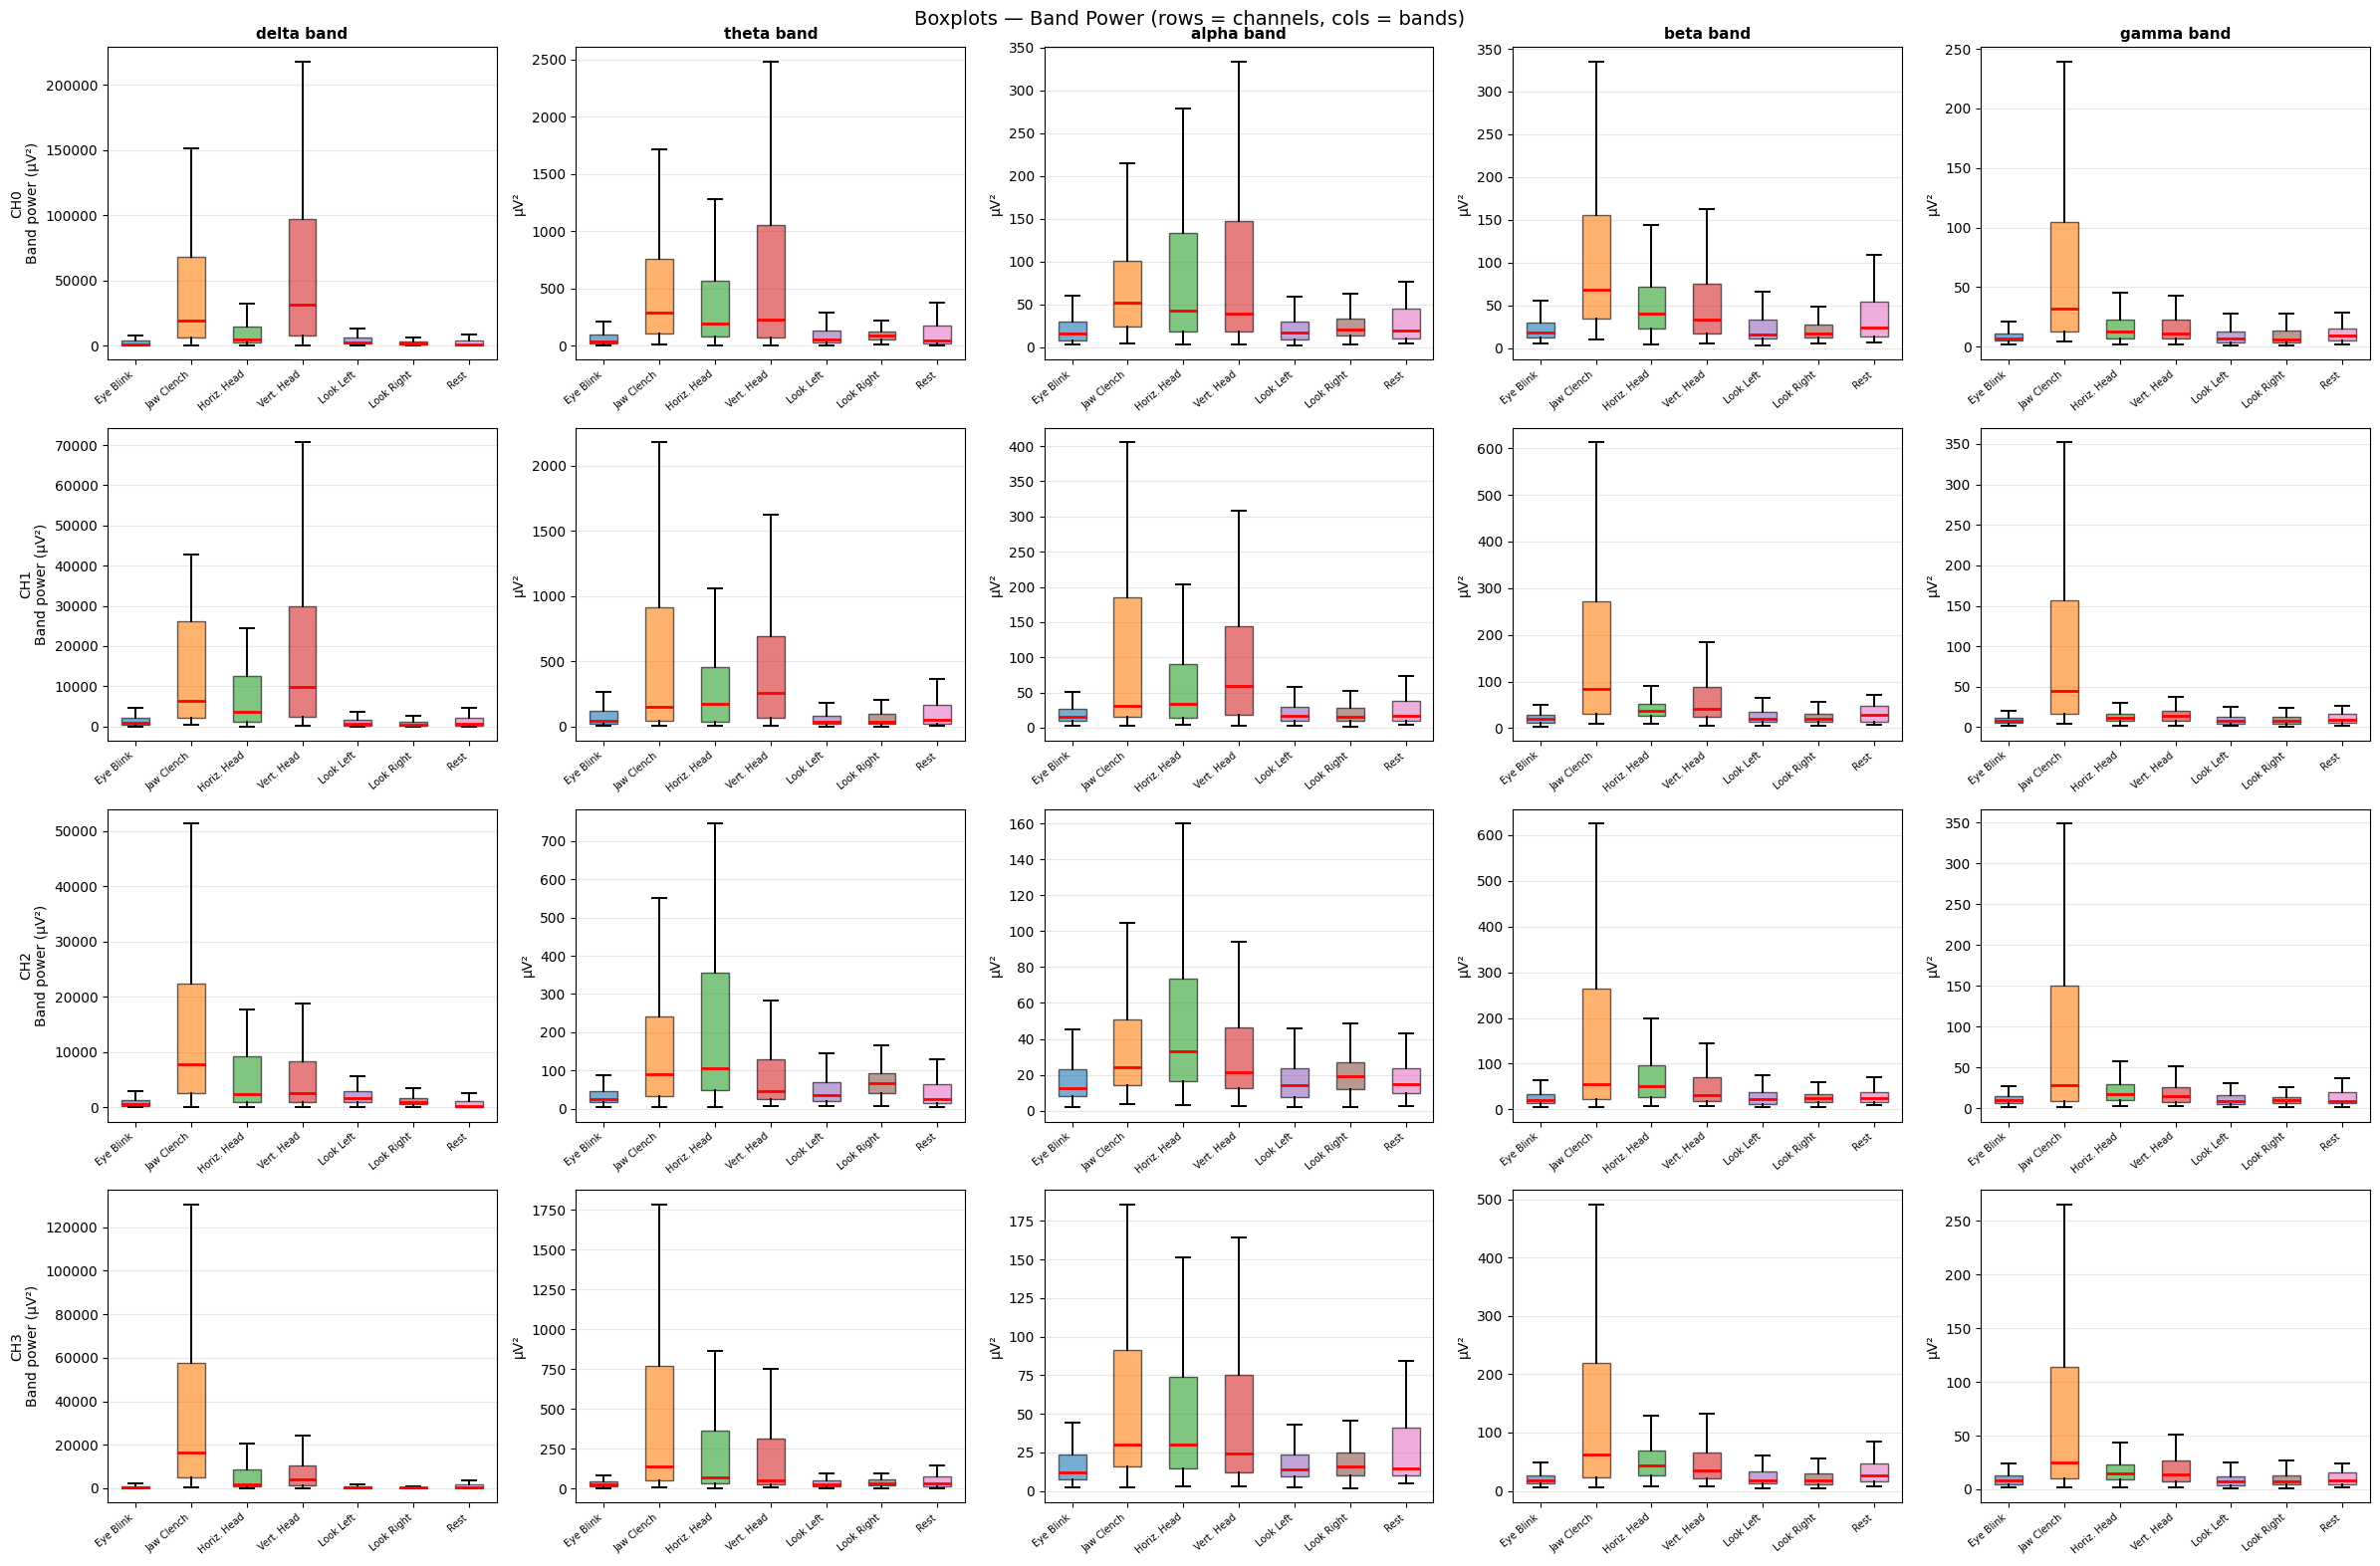

In [20]:
# Boxplots — band power, rows = channels, cols = bands
fig, axes = plt.subplots(len(CH), len(BAND_FEATS),
                          figsize=(24, 4 * len(CH)), sharey=False)

art_labels_list = list(ART_LABELS.values()) + [REST_LABEL]

for ri, ch in enumerate(CH):
    df_ch = feat_full[feat_full['channel'] == ch]
    for ci, (bname, _) in enumerate(BANDS.items()):
        ax = axes[ri, ci]
        feat = f'bp_{bname}'
        data = [df_ch.loc[df_ch['artifact'] == lbl, feat].dropna().values
                for lbl in art_labels_list]
        bp = ax.boxplot(data, labels=art_labels_list,
                        patch_artist=True, showfliers=False,
                        medianprops=dict(color='red', linewidth=2),
                        whiskerprops=dict(linewidth=1.4),
                        capprops=dict(linewidth=1.4))
        for patch, col in zip(bp['boxes'], COLORS[:len(art_labels_list)]):
            patch.set_facecolor(col)
            patch.set_alpha(0.6)
        ax.set_xticklabels(art_labels_list, rotation=40, ha='right', fontsize=7)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_ylabel('µV²')
        if ri == 0:
            ax.set_title(f'{bname} band', fontsize=11, fontweight='bold')
        if ci == 0:
            ax.set_ylabel(f'{ch}\nBand power (µV²)', fontsize=10)

fig.suptitle('Boxplots — Band Power (rows = channels, cols = bands)', fontsize=14)
plt.tight_layout()
plt.show()


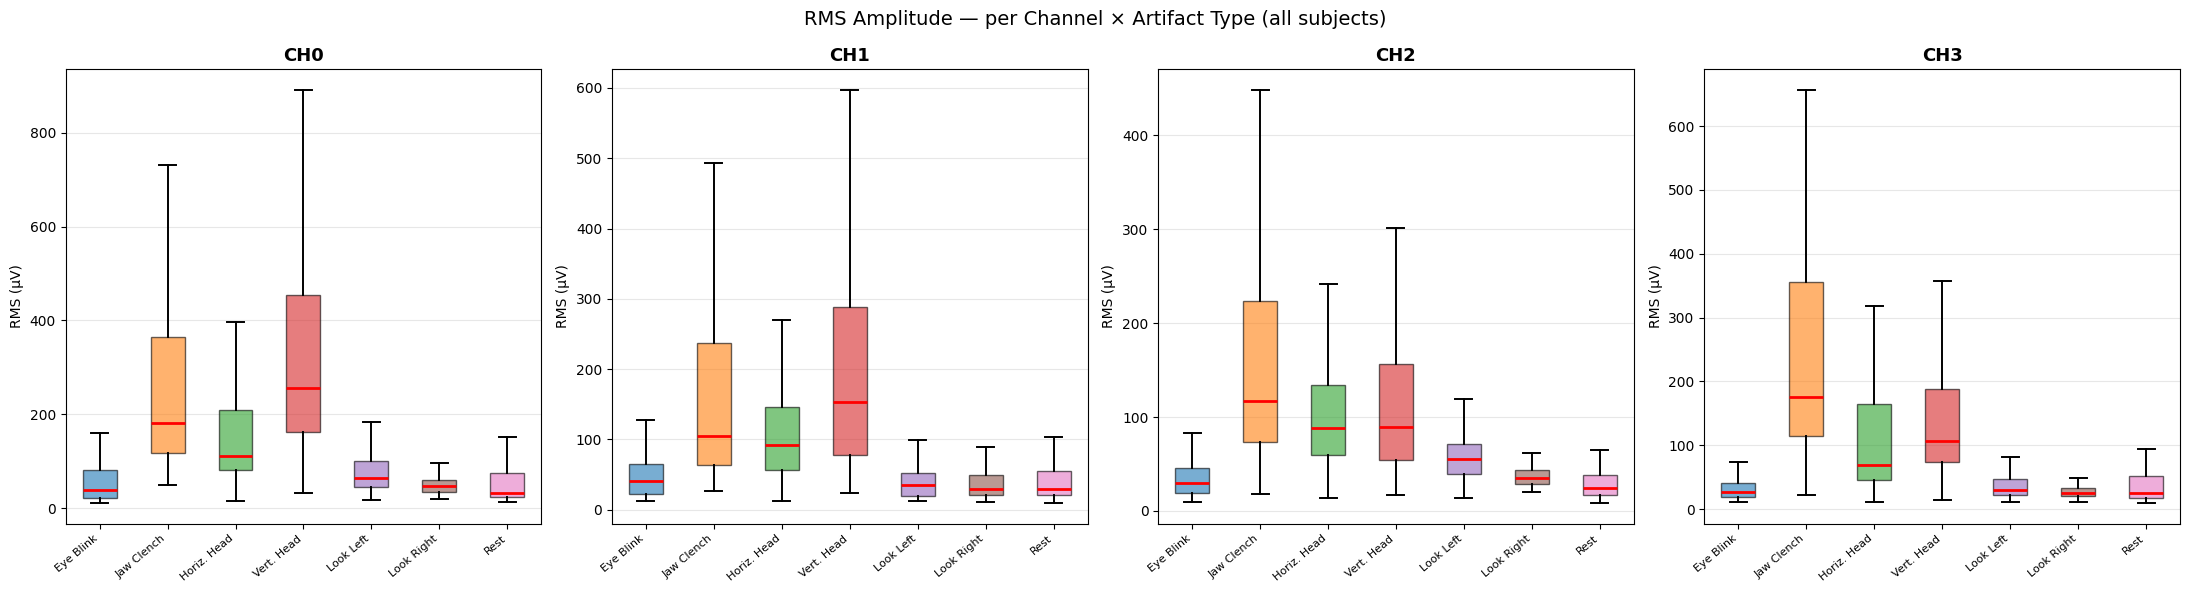

In [21]:
# RMS boxplots — one panel per channel
rms_rows = []
for ep in all_epochs:
    event = ep['artifact'].iloc[0]
    label = ART_LABELS[event] if event in ART_LABELS else REST_LABEL
    for ch in CH:
        x = ep[ch].values.astype(float)
        rms_rows.append({'artifact': label, 'channel': ch,
                         'rms': float(np.sqrt(np.mean(x**2)))})
art_labels_list = list(ART_LABELS.values()) + [REST_LABEL]
rms_df = pd.DataFrame(rms_rows)

fig, axes = plt.subplots(1, 4, figsize=(22, 6), sharey=False)
for ax, ch in zip(axes, CH):
    data = [rms_df.loc[(rms_df['channel']==ch)&(rms_df['artifact']==lbl), 'rms'].values
            for lbl in art_labels_list]
    bp = ax.boxplot(data, labels=art_labels_list,
                    patch_artist=True, showfliers=False,
                    medianprops=dict(color='red', linewidth=2),
                    whiskerprops=dict(linewidth=1.4),
                    capprops=dict(linewidth=1.4))
    for patch, col in zip(bp['boxes'], COLORS[:len(art_labels_list)]):
        patch.set_facecolor(col)
        patch.set_alpha(0.6)
    ax.set_title(ch, fontsize=13, fontweight='bold')
    ax.set_ylabel('RMS (µV)')
    ax.set_xticklabels(art_labels_list, rotation=40, ha='right', fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')

fig.suptitle('RMS Amplitude — per Channel × Artifact Type (all subjects)', fontsize=14)
plt.tight_layout()
plt.show()


In [22]:
# Summary statistics table — mean per artifact × channel
summary_final = (
    feat_full.groupby(['artifact','channel'])[ALL_FEATS]
    .agg(['mean','std'])
)
summary_final.columns = ['_'.join(c) for c in summary_final.columns]
print('Final feature summary — per artifact × channel:')
display(summary_final.round(3))

Final feature summary — per artifact × channel:


rms_mean  rms_std  p2p_mean   p2p_std  kurtosis_mean  \
artifact    channel                                                         
Eye Blink   CH0        61.675   59.580   307.537   298.289          1.167   
            CH1        53.436   50.731   266.490   255.386          0.928   
            CH2        43.240   43.998   233.812   231.130          1.676   
            CH3        41.139   44.775   218.358   234.123          1.189   
Horiz. Head CH0       279.723  674.234  1275.124  2822.720          0.454   
            CH1       147.719  147.046   711.170   685.136          0.537   
            CH2       128.809  111.402   637.663   599.057          0.423   
            CH3       202.225  353.413   959.426  1574.307          0.491   
Jaw Clench  CH0       273.341  292.674  1184.099  1167.093          0.744   
            CH1       181.350  186.289   842.276   811.440          0.855   
            CH2       227.270  303.820   959.360  1098.554          0.520   
            CH3       261.466  242.454  1118.836   977.538          0.400   
Look Left   CH0        93.528  192.095   434.691  1035.345          0.065   
            CH1        63.654  197.810   327.329  1056.872          0.379   
            CH2        78.122  192.523   378.399  1036.008          0.161   
            CH3        58.677  198.107   311.836  1064.995          0.423   
Look Right  CH0        52.582   26.860   238.061   131.653         -0.453   
            CH1        43.222   36.397   217.605   184.989          0.179   
            CH2        37.553   12.968   181.189    59.445         -0.291   
            CH3        29.045   14.207   159.902    75.705          0.360   
Rest        CH0       105.177  351.794   558.525  1958.980          0.574   
            CH1        56.117   69.160   285.320   379.010          0.083   
            CH2        42.151   67.418   218.834   299.418          0.524   
            CH3        59.475   98.567   310.597   563.573          0.520   
Vert. Head  CH0       404.784  536.257  1670.360  2254.663         -0.281   
            CH1       227.391  209.038   998.979   834.142          0.560   
            CH2       145.941  171.718   636.274   666.291          0.233   
            CH3       169.151  186.727   752.514   750.554          0.366   

                     kurtosis_std  skewness_mean  skewness_std    var_mean  \
artifact    channel                                                          
Eye Blink   CH0             1.917          0.832         0.644    7262.941   
            CH1             1.860          0.782         0.597    5379.071   
            CH2             1.995          0.943         0.686    3769.081   
            CH3             1.875          0.781         0.606    3659.997   
Horiz. Head CH0             4.399          0.499         0.614  522979.433   
            CH1             4.233          0.448         0.630   42892.894   
            CH2             4.309          0.475         0.650   28746.359   
            CH3             4.287          0.484         0.625  162449.197   
Jaw Clench  CH0             2.348          0.701         0.509  157441.781   
            CH1             2.081          0.828         0.581   66201.756   
            CH2             1.792          0.757         0.588  141079.090   
            CH3             1.416          0.840         0.552  124833.380   
Look Left   CH0             1.205          0.683         0.438   45127.073   
            CH1             1.665          0.490         0.440   42670.834   
            CH2             1.123          0.721         0.422   42665.729   
            CH3             1.427          0.515         0.417   42185.865   
Look Right  CH0             1.072          0.432         0.343    3458.292   
            CH1             1.591          0.474         0.390    3167.014   
            CH2             0.690          0.498         0.347    1561.885   
            CH3             1.565          0.485         0.378    1031.4